In [1]:
# ============================================================================
# TextCNN: Multi-Kernel Convolutional Neural Network
# Multi-Task Complaint Classification (Primary / Sub-category / Severity)
# Converted from the MBERT notebook - trained from scratch, no pretrained model
# Results are reported for the COMMON (combined) text and for each language
# (English / Hindi / Hinglish) separately, for every task and every class.
# ============================================================================

# ----------------------------------------------------------------------------
# CELL 1: IMPORTS AND SYSTEM SETUP
# ----------------------------------------------------------------------------

import os
import re
import sys
import math
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import pickle
import json
import random
from collections import Counter
from datetime import datetime
import time

# PyTorch imports
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.optim.lr_scheduler import LambdaLR
from torch.amp import GradScaler, autocast

# Scikit-learn
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    balanced_accuracy_score,
    cohen_kappa_score,
    matthews_corrcoef,
    precision_recall_fscore_support
)
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA

# Set random seeds
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

set_seed(42)

# Device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\n{'='*80}")
print(f"SYSTEM INFORMATION")
print(f"{'='*80}")
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"CUDA device: {torch.cuda.get_device_name(0)}")
    print(f"CUDA memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
print(f"Using device: {device}")
print(f"{'='*80}\n")



SYSTEM INFORMATION
PyTorch version: 2.6.0+cu126
CUDA available: True
CUDA device: NVIDIA GeForce RTX 3070
CUDA memory: 8.59 GB
Using device: cuda



In [2]:
# ----------------------------------------------------------------------------
# CELL 2: CONFIGURATION
# ----------------------------------------------------------------------------

class Config:
    """Configuration settings for the TextCNN model"""

    BASE_MODEL = 'cnn'

    # Directories
    PROJECT_DIR = os.getcwd()
    DATA_DIR = os.path.join(PROJECT_DIR, "Common_Dataset")
    TRAIN_PATH = os.path.join(DATA_DIR, "train.csv")
    DEV_PATH = os.path.join(DATA_DIR, "dev.csv")
    TEST_PATH = os.path.join(DATA_DIR, "test.csv")

    # Output - separate directory for CNN results
    BASE_DIR = os.path.join(PROJECT_DIR, "cnn_results_common")
    MODEL_DIR = os.path.join(BASE_DIR, "models")
    VISUALIZATION_DIR = os.path.join(BASE_DIR, "visualizations")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")

    for dir_path in [BASE_DIR, MODEL_DIR, VISUALIZATION_DIR, RESULTS_DIR]:
        os.makedirs(dir_path, exist_ok=True)

    # Vocabulary (word level, built from the training split only)
    MAX_LENGTH = 256          # starting value; CELL 6 re-sets it from the data
    MAX_LENGTH_CAP = 400      # upper bound for the data-driven MAX_LENGTH
    MAX_VOCAB_SIZE = 50000
    MIN_FREQ = 2

    # Language name -> column in the PREPROCESSED dataframes (after the rename in CELL 5)
    LANGUAGE_COLUMNS = {'English': 'text_en', 'Hindi': 'Hindi', 'Hinglish': 'Hinglish'}

    # TextCNN architecture
    EMBEDDING_DIM = 300
    NUM_FILTERS = 128                 # filters per kernel size
    KERNEL_SIZES = (2, 3, 4, 5)       # n-gram widths
    DROPOUT = 0.3
    EMBED_DROPOUT = 0.2

    # Training
    BATCH_SIZE = 64
    EPOCHS = 30
    LEARNING_RATE = 1e-3
    WEIGHT_DECAY = 1e-4
    WARMUP_RATIO = 0.1
    PATIENCE = 6
    GRAD_CLIP = 1.0
    NUM_WORKERS = 0  # Set to 0 for Windows compatibility

    # Device
    DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    SEED = 42


print("=" * 80)
print("TextCNN CONFIGURATION")
print("=" * 80)
print(f"\n[BATCH SIZE] {Config.BATCH_SIZE}")
print(f"[EPOCHS] {Config.EPOCHS}")
print(f"[LEARNING RATE] {Config.LEARNING_RATE}")
print(f"[EMBEDDING DIM] {Config.EMBEDDING_DIM}")
print(f"[FILTERS x KERNELS] {Config.NUM_FILTERS} x {Config.KERNEL_SIZES}")
print(f"[DEVICE] {Config.DEVICE}")
print("=" * 80)


TextCNN CONFIGURATION

[BATCH SIZE] 64
[EPOCHS] 30
[LEARNING RATE] 0.001
[EMBEDDING DIM] 300
[FILTERS x KERNELS] 128 x (2, 3, 4, 5)
[DEVICE] cuda


In [3]:
# ----------------------------------------------------------------------------
# CELL 3: LOAD DATA
# ----------------------------------------------------------------------------

print("Loading datasets...")
train_df = pd.read_csv(Config.TRAIN_PATH)
dev_df = pd.read_csv(Config.DEV_PATH)
test_df = pd.read_csv(Config.TEST_PATH)
print(f"Train: {len(train_df)}, Dev: {len(dev_df)}, Test: {len(test_df)}")

# Quick distribution
print("\nPrimary Category Distribution (Train):")
print(train_df['primary_category'].value_counts())

print("\nSeverity Distribution (Train):")
print(train_df['Severity'].value_counts())

Loading datasets...
Train: 14165, Dev: 3035, Test: 3036

Primary Category Distribution (Train):
primary_category
Road & Transportation                  2710
Waste Management                       2075
Electricity                            1908
Others                                 1616
Water Leakage                          1573
Health & Sanitation                    1470
Public Safety                          1408
Encroachment & Illegal Construction    1405
Name: count, dtype: int64

Severity Distribution (Train):
Severity
Low       5898
Medium    4290
High      3977
Name: count, dtype: int64


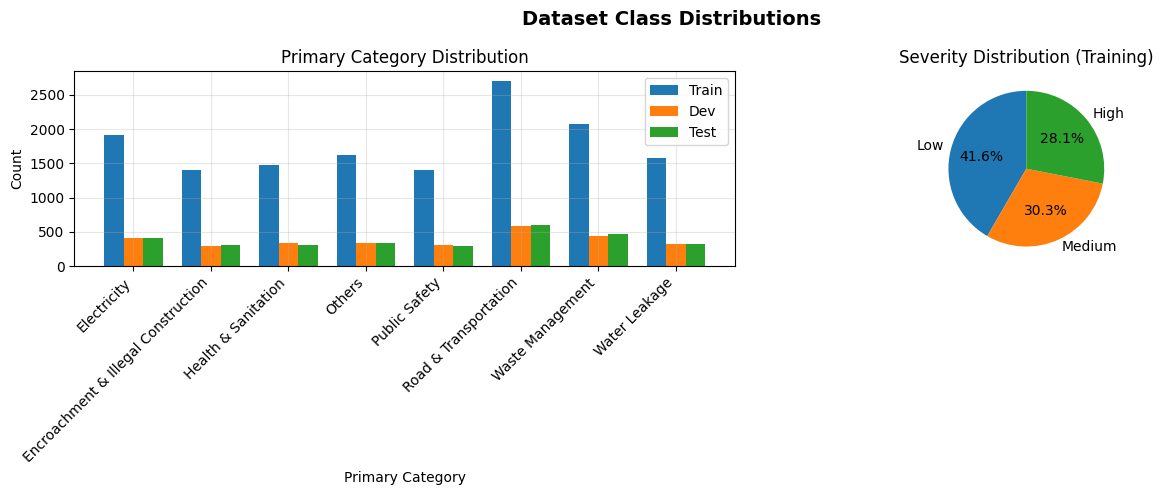

In [4]:
# ----------------------------------------------------------------------------
# CELL 4: VISUALIZE CLASS DISTRIBUTIONS
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Primary categories
train_counts = train_df['primary_category'].value_counts()
dev_counts = dev_df['primary_category'].value_counts()
test_counts = test_df['primary_category'].value_counts()

categories = sorted(train_counts.index.tolist())
x = np.arange(len(categories))
width = 0.25

axes[0].bar(x - width, [train_counts.get(c, 0) for c in categories], width, label='Train')
axes[0].bar(x, [dev_counts.get(c, 0) for c in categories], width, label='Dev')
axes[0].bar(x + width, [test_counts.get(c, 0) for c in categories], width, label='Test')
axes[0].set_xlabel('Primary Category')
axes[0].set_ylabel('Count')
axes[0].set_title('Primary Category Distribution')
axes[0].set_xticks(x)
axes[0].set_xticklabels(categories, rotation=45, ha='right')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Severity
severity_counts = train_df['Severity'].value_counts()
axes[1].pie(severity_counts.values, labels=severity_counts.index, 
            autopct='%1.1f%%', startangle=90)
axes[1].set_title('Severity Distribution (Training)')

plt.suptitle('Dataset Class Distributions', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/class_distributions.png", dpi=300, bbox_inches='tight')
plt.show()

In [5]:
# ----------------------------------------------------------------------------
# CELL 5: PREPROCESS DATA
# ----------------------------------------------------------------------------

class Preprocessor:
    def __init__(self):
        self.le_primary = LabelEncoder()
        self.le_subcat = LabelEncoder()
        self.le_severity = LabelEncoder()
        
        self.column_mapping = {
            'primary_category': 'category_primary',
            'secondary_category': 'category_secondary',
            'Severity': 'severity',
            'Complaint_Title': 'complaint_title',
            'Text_en': 'text_en',
            'Text_hi': 'Hindi',
            'Text_hinglish': 'Hinglish'
        }
    
    def preprocess_text(self, df):
        rename_dict = {k: v for k, v in self.column_mapping.items() if k in df.columns}
        if rename_dict:
            df = df.rename(columns=rename_dict)
        
        text_cols = ['complaint_title', 'text_en', 'Hindi', 'Hinglish']
        for col in text_cols:
            if col in df.columns:
                df[col] = df[col].fillna('').astype(str)
        
        missing = [col for col in text_cols if col not in df.columns]
        if missing:
            raise ValueError(f"Text columns missing after rename: {missing}. "
                             f"Available columns: {list(df.columns)}")
        available_cols = [col for col in text_cols if col in df.columns]
        if available_cols:
            df["text"] = df[available_cols].agg(" ".join, axis=1)
            df["text"] = df["text"].str.replace(r"\s+", " ", regex=True).str.strip()
        
        df = df.dropna(subset=["category_primary", "category_secondary", "severity"])
        return df.reset_index(drop=True)
    
    def prepare_labels(self, train_df, dev_df, test_df):
        print("Preparing labels...")
        self.le_primary.fit(train_df['category_primary'])
        self.le_subcat.fit(train_df['category_secondary'])
        self.le_severity.fit(train_df['severity'])
        
        print(f"Primary: {len(self.le_primary.classes_)}, "
              f"Subcat: {len(self.le_subcat.classes_)}, "
              f"Severity: {len(self.le_severity.classes_)})")
        
        for df in [train_df, dev_df, test_df]:
            df["primary_label"] = self.le_primary.transform(df["category_primary"])
            df["subcat_label"] = self.le_subcat.transform(df["category_secondary"])
            df["severity_label"] = self.le_severity.transform(df["severity"])
            df["sentiment_score"] = 0.0
        
        return train_df, dev_df, test_df
    
    def process_data(self, train_df, dev_df, test_df):
        print("Preprocessing text...")
        train_df = self.preprocess_text(train_df)
        dev_df = self.preprocess_text(dev_df)
        test_df = self.preprocess_text(test_df)
        
        train_df, dev_df, test_df = self.prepare_labels(train_df, dev_df, test_df)
        print(f"Final: Train {len(train_df)}, Dev {len(dev_df)}, Test {len(test_df)}")
        return train_df, dev_df, test_df

preprocessor = Preprocessor()
train_df, dev_df, test_df = preprocessor.process_data(train_df, dev_df, test_df)
print("✅ Data preprocessing completed")

# Sanity check: the combined text must contain ALL four text columns
print("Combined text = complaint_title + text_en + Hindi + Hinglish")
print("Example:", train_df["text"].iloc[0][:300], "...")


Preprocessing text...
Preparing labels...
Primary: 8, Subcat: 24, Severity: 3)
Final: Train 14165, Dev 3035, Test 3036
✅ Data preprocessing completed
Combined text = complaint_title + text_en + Hindi + Hinglish
Example: Toilet Near Lane Facing Weekly Backup Issues The public toilet near a lane in Saidapet has been experiencing weekly backup issues due to grease buildup in the connecting drain. Residents say the smell and mess have become a regular occurrence that needs proper resolution. सैदापेट में एक गली के पास स ...


In [6]:
# ----------------------------------------------------------------------------
# CELL 6: BUILD VOCABULARY (replaces the BERT tokenizer)
# ----------------------------------------------------------------------------

class Vocabulary:
    """Simple word-level vocabulary for the CNN (English, Devanagari Hindi, Hinglish)"""

    PAD_TOKEN = "<pad>"
    UNK_TOKEN = "<unk>"
    PAD_IDX = 0
    UNK_IDX = 1

    def __init__(self, max_size=50000, min_freq=2):
        self.max_size = max_size
        self.min_freq = min_freq
        self.word2idx = {self.PAD_TOKEN: self.PAD_IDX, self.UNK_TOKEN: self.UNK_IDX}
        self.idx2word = {self.PAD_IDX: self.PAD_TOKEN, self.UNK_IDX: self.UNK_TOKEN}
        self.word_freq = Counter()

    @staticmethod
    def tokenize(text):
        """Lowercase; words = Latin/digit/Devanagari runs; every other symbol is its own token.
        The Hindi danda (U+0964) is excluded from the word range so it is split off."""
        text = str(text).lower()
        return re.findall(r"[a-zA-Z0-9\u0900-\u0963\u0966-\u097F]+|[^\sa-zA-Z0-9\u0900-\u0963\u0966-\u097F]", text)

    def build_vocab(self, texts):
        print("Building vocabulary...")
        for text in tqdm(texts, desc="Counting tokens"):
            self.word_freq.update(self.tokenize(text))

        idx = 2  # 0=pad, 1=unk
        for word, freq in sorted(self.word_freq.items(), key=lambda x: x[1], reverse=True):
            if freq < self.min_freq or idx >= self.max_size:
                break
            self.word2idx[word] = idx
            self.idx2word[idx] = word
            idx += 1

        print(f"✅ Vocabulary size: {len(self.word2idx)}")
        return self

    def encode(self, text, max_length):
        ids = [self.word2idx.get(t, self.UNK_IDX) for t in self.tokenize(text)][:max_length]
        if len(ids) == 0:                       # never return an all-padding sequence
            ids = [self.UNK_IDX]
        return ids + [self.PAD_IDX] * (max_length - len(ids))

    def __len__(self):
        return len(self.word2idx)


# Build vocab on training data only
vocab = Vocabulary(max_size=Config.MAX_VOCAB_SIZE, min_freq=Config.MIN_FREQ)
vocab.build_vocab(train_df["text"].astype(str).tolist())

# ----------------------------------------------------------------------------
# Choose MAX_LENGTH from the data. The combined text is
#   title + English + Hindi + Hinglish,
# so a too-small limit silently cuts off the Hindi/Hinglish part.
# ----------------------------------------------------------------------------
train_lengths = np.array([len(Vocabulary.tokenize(t)) for t in train_df["text"]])
auto_len = int(np.ceil(np.percentile(train_lengths, 98) / 16) * 16)
Config.MAX_LENGTH = int(min(Config.MAX_LENGTH_CAP, max(64, auto_len, max(Config.KERNEL_SIZES))))

print(f"\nCombined text length (tokens): mean={train_lengths.mean():.0f}, "
      f"95th pct={np.percentile(train_lengths, 95):.0f}, max={train_lengths.max()}")
print(f"MAX_LENGTH set to {Config.MAX_LENGTH}  "
      f"({(train_lengths > Config.MAX_LENGTH).mean():.1%} of training samples truncated)")

print("\nPer-language text length (tokens) in the training set:")
for lang, col in Config.LANGUAGE_COLUMNS.items():
    lens = np.array([len(Vocabulary.tokenize(t)) for t in train_df[col]])
    print(f"  {lang:<9} mean={lens.mean():6.1f}  max={lens.max():4d}")


Building vocabulary...


Counting tokens: 100%|██████████| 14165/14165 [00:00<00:00, 17394.43it/s]


✅ Vocabulary size: 29763

Combined text length (tokens): mean=132, 95th pct=239, max=2590
MAX_LENGTH set to 368  (1.9% of training samples truncated)

Per-language text length (tokens) in the training set:
  English   mean=  37.6  max=1647
  Hindi     mean=  45.4  max= 877
  Hinglish  mean=  42.7  max= 877


In [7]:
# ----------------------------------------------------------------------------
# CELL 7: PRE-ENCODED DATASET CLASS (word-id version)
# ----------------------------------------------------------------------------

class PreTokenizedDataset(Dataset):
    """
    Pre-encodes all text to word-id sequences once.
    text_col selects which column is encoded:
      'text'  -> combined text (training / common evaluation)
      'text_en' / 'Hindi' / 'Hinglish' -> a single language (language-wise evaluation)
    """

    def __init__(self, df, vocab, max_length=128, text_col="text"):
        print(f"Pre-encoding dataset (text column: '{text_col}')...")
        self.primary = torch.tensor(df["primary_label"].values, dtype=torch.long)
        self.subcat = torch.tensor(df["subcat_label"].values, dtype=torch.long)
        self.severity = torch.tensor(df["severity_label"].values, dtype=torch.long)

        texts = df[text_col].astype(str).tolist()
        encoded = [vocab.encode(t, max_length) for t in texts]

        self.input_ids = torch.tensor(encoded, dtype=torch.long)
        # Attention mask: 1 for real tokens, 0 for padding
        self.attention_mask = (self.input_ids != Vocabulary.PAD_IDX).long()
        self.sentiment = torch.zeros(len(df), dtype=torch.float)

        print(f"✅ Pre-encoded {len(df)} samples")

    def __len__(self):
        return len(self.primary)

    def __getitem__(self, idx):
        return {
            "input_ids": self.input_ids[idx],
            "attention_mask": self.attention_mask[idx],
            "primary": self.primary[idx],
            "subcat": self.subcat[idx],
            "severity": self.severity[idx],
            "sentiment": self.sentiment[idx]
        }


In [8]:
# ----------------------------------------------------------------------------
# CELL 8: TextCNN MULTI-TASK MODEL
# ----------------------------------------------------------------------------

class TextCNNMultiTask(nn.Module):
    """
    TextCNN for multi-task classification:
    - Primary category classification (8 classes)
    - Sub-category classification (24 classes)
    - Severity classification (3 classes)

    Architecture:
      Embedding -> parallel Conv1d (kernel sizes 2,3,4,5) + ReLU
      -> masked global max-pooling over time -> concat -> LayerNorm
      -> shared dense layer (GELU + dropout) -> 3 task heads
    Same forward signature and outputs as the MBERT model.
    """

    def __init__(self, vocab_size, embedding_dim, num_filters, kernel_sizes,
                 n_primary, n_subcat, n_severity, dropout=0.3, embed_dropout=0.2, pad_idx=0):
        super().__init__()
        self.pad_idx = pad_idx
        self.kernel_sizes = tuple(kernel_sizes)

        self.embedding = nn.Embedding(vocab_size, embedding_dim, padding_idx=pad_idx)
        self.embed_dropout = nn.Dropout(embed_dropout)

        self.convs = nn.ModuleList([
            nn.Conv1d(embedding_dim, num_filters, kernel_size=k) for k in self.kernel_sizes
        ])

        conv_out_dim = num_filters * len(self.kernel_sizes)
        self.layer_norm = nn.LayerNorm(conv_out_dim)

        hidden_size = conv_out_dim
        self.dropout = nn.Dropout(dropout)
        self.shared = nn.Linear(conv_out_dim, hidden_size)
        self.gelu = nn.GELU()

        # Multi-task classification heads
        self.fc_primary = nn.Linear(hidden_size, n_primary)
        self.fc_subcat = nn.Linear(hidden_size, n_subcat)
        self.fc_severity = nn.Linear(hidden_size, n_severity)

        self.n_primary = n_primary
        self.n_subcat = n_subcat
        self.n_severity = n_severity
        self.hidden_size = hidden_size

        self.config_dict = dict(
            vocab_size=vocab_size, embedding_dim=embedding_dim, num_filters=num_filters,
            kernel_sizes=list(self.kernel_sizes), n_primary=n_primary, n_subcat=n_subcat,
            n_severity=n_severity, dropout=dropout, embed_dropout=embed_dropout, pad_idx=pad_idx
        )

        self._init_weights()

    def _init_weights(self):
        nn.init.normal_(self.embedding.weight, mean=0.0, std=0.1)
        with torch.no_grad():
            self.embedding.weight[self.pad_idx].fill_(0)
        for conv in self.convs:
            nn.init.xavier_uniform_(conv.weight)
            nn.init.zeros_(conv.bias)
        for module in [self.shared, self.fc_primary, self.fc_subcat, self.fc_severity]:
            nn.init.xavier_uniform_(module.weight)
            nn.init.zeros_(module.bias)

    def _encode(self, input_ids, attention_mask):
        """Embedding + convolutions + masked max-pooling -> [B, num_filters * n_kernels]."""
        lengths = attention_mask.sum(dim=1)                          # [B] real tokens per sample
        x = self.embed_dropout(self.embedding(input_ids))            # [B, L, E]
        x = x.transpose(1, 2)                                        # [B, E, L]

        pooled = []
        for conv, k in zip(self.convs, self.kernel_sizes):
            h = F.relu(conv(x)).float()                              # [B, F, L-k+1]
            T = h.size(2)
            # A window starting at t is valid only if it lies fully inside the real tokens.
            # Without this mask, windows over padding would dominate the max-pool for short texts
            # (important for the single-language evaluation, where texts are much shorter).
            pos = torch.arange(T, device=h.device).unsqueeze(0)      # [1, T]
            valid = (pos + k) <= lengths.unsqueeze(1)                # [B, T]
            valid[:, 0] = True                                       # texts shorter than k keep window 0
            h = h.masked_fill(~valid.unsqueeze(1), -1e4)
            pooled.append(h.max(dim=2).values)                       # [B, F]

        return torch.cat(pooled, dim=1)

    def forward(self, input_ids, attention_mask, sentiment=None):
        """
        Returns:
            Tuple of (primary_logits, subcat_logits, severity_logits)
        """
        feats = self.layer_norm(self._encode(input_ids, attention_mask))
        x = self.gelu(self.shared(feats))
        x = self.dropout(x)
        return self.fc_primary(x), self.fc_subcat(x), self.fc_severity(x)

    def get_embeddings(self, input_ids, attention_mask):
        """Extract shared sentence representations for visualization"""
        with torch.no_grad():
            feats = self.layer_norm(self._encode(input_ids, attention_mask))
            return self.gelu(self.shared(feats))


# Build model
n_primary = len(preprocessor.le_primary.classes_)
n_subcat = len(preprocessor.le_subcat.classes_)
n_severity = len(preprocessor.le_severity.classes_)

model = TextCNNMultiTask(
    vocab_size=len(vocab),
    embedding_dim=Config.EMBEDDING_DIM,
    num_filters=Config.NUM_FILTERS,
    kernel_sizes=Config.KERNEL_SIZES,
    n_primary=n_primary,
    n_subcat=n_subcat,
    n_severity=n_severity,
    dropout=Config.DROPOUT,
    embed_dropout=Config.EMBED_DROPOUT,
    pad_idx=Vocabulary.PAD_IDX
).to(Config.DEVICE)

print(f"✅ TextCNN model created: {sum(p.numel() for p in model.parameters()):,} parameters")
print(f"   Vocab size: {len(vocab)}")
print(f"   Embedding dim: {Config.EMBEDDING_DIM}")
print(f"   Filters: {Config.NUM_FILTERS} x kernel sizes {Config.KERNEL_SIZES}")


✅ TextCNN model created: 9,748,647 parameters
   Vocab size: 29763
   Embedding dim: 300
   Filters: 128 x kernel sizes (2, 3, 4, 5)


In [9]:
# ----------------------------------------------------------------------------
# CELL 9: CREATE DATALOADERS WITH PRE-TOKENIZATION
# ----------------------------------------------------------------------------

print("Creating pre-encoded datasets...")
train_dataset = PreTokenizedDataset(train_df, vocab, Config.MAX_LENGTH)
dev_dataset = PreTokenizedDataset(dev_df, vocab, Config.MAX_LENGTH)
test_dataset = PreTokenizedDataset(test_df, vocab, Config.MAX_LENGTH)

# Create dataloaders
train_loader = DataLoader(
    train_dataset, 
    batch_size=Config.BATCH_SIZE, 
    shuffle=True,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
dev_loader = DataLoader(
    dev_dataset, 
    batch_size=Config.BATCH_SIZE * 2, 
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)
test_loader = DataLoader(
    test_dataset, 
    batch_size=Config.BATCH_SIZE * 2, 
    shuffle=False,
    num_workers=Config.NUM_WORKERS,
    pin_memory=True
)

print(f"Train batches: {len(train_loader)}, Dev: {len(dev_loader)}, Test: {len(test_loader)}")

# Test one batch
print("\nTesting data loader...")
test_batch = next(iter(train_loader))
print(f"✅ First batch loaded successfully!")
print(f"Input shape: {test_batch['input_ids'].shape}")
print(f"Labels shapes: Primary={test_batch['primary'].shape}, "
      f"Subcat={test_batch['subcat'].shape}, "
      f"Severity={test_batch['severity'].shape}")
print("✅ Data loader working!")

Creating pre-encoded datasets...
Pre-encoding dataset (text column: 'text')...
✅ Pre-encoded 14165 samples
Pre-encoding dataset (text column: 'text')...
✅ Pre-encoded 3035 samples
Pre-encoding dataset (text column: 'text')...
✅ Pre-encoded 3036 samples
Train batches: 222, Dev: 24, Test: 24

Testing data loader...
✅ First batch loaded successfully!
Input shape: torch.Size([64, 368])
Labels shapes: Primary=torch.Size([64]), Subcat=torch.Size([64]), Severity=torch.Size([64])
✅ Data loader working!


In [10]:
# ----------------------------------------------------------------------------
# CELL 10: TRAINING FUNCTIONS
# ----------------------------------------------------------------------------

class MultiTaskLoss(nn.Module):
    def __init__(self):
        super().__init__()
        self.primary_loss = nn.CrossEntropyLoss()
        self.subcat_loss = nn.CrossEntropyLoss()
        self.severity_loss = nn.CrossEntropyLoss()
        self.primary_weight = 1.0
        self.subcat_weight = 1.0
        self.severity_weight = 0.5
    
    def forward(self, p1, p2, p3, y1, y2, y3):
        loss1 = self.primary_loss(p1, y1)
        loss2 = self.subcat_loss(p2, y2)
        loss3 = self.severity_loss(p3, y3)
        total = self.primary_weight * loss1 + self.subcat_weight * loss2 + self.severity_weight * loss3
        return total, {'primary': loss1.item(), 'subcat': loss2.item(), 'severity': loss3.item()}

criterion = MultiTaskLoss()


class EarlyStopping:
    """Early stops training if validation metric doesn't improve after a given patience."""
    def __init__(self, patience=5, min_delta=0.001, mode='max'):
        self.patience = patience
        self.min_delta = min_delta
        self.mode = mode
        self.counter = 0
        self.best_score = None
        self.early_stop = False
    
    def __call__(self, score):
        if self.best_score is None:
            self.best_score = score
            return False
        
        if self.mode == 'max':
            improvement = score - self.best_score > self.min_delta
        else:
            improvement = self.best_score - score > self.min_delta
        
        if improvement:
            self.best_score = score
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop


def train_epoch_optimized(model, dataloader, optimizer, scheduler, criterion, device, scaler):
    """Optimized training with mixed precision"""
    model.train()
    total_loss = 0
    all_preds, all_labels = [], []
    task_losses = {'primary': 0, 'subcat': 0, 'severity': 0}
    
    progress_bar = tqdm(dataloader, desc='Training', leave=False)
    
    for batch in progress_bar:
        input_ids = batch['input_ids'].to(device, non_blocking=True)
        attention_mask = batch['attention_mask'].to(device, non_blocking=True)
        y_primary = batch['primary'].to(device, non_blocking=True)
        y_subcat = batch['subcat'].to(device, non_blocking=True)
        y_severity = batch['severity'].to(device, non_blocking=True)
        
        # Mixed precision forward pass
        with autocast(device_type=device.type, enabled=scaler.is_enabled()):
            p1, p2, p3 = model(input_ids, attention_mask)
            loss, loss_dict = criterion(p1, p2, p3, y_primary, y_subcat, y_severity)
        
        # Mixed precision backward pass
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=Config.GRAD_CLIP)
        scaler.step(optimizer)
        scaler.update()
        scheduler.step()
        optimizer.zero_grad(set_to_none=True)
        
        total_loss += loss.item()
        for key in task_losses:
            task_losses[key] += loss_dict.get(key, 0)
        
        preds = torch.argmax(p1, dim=1)
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(y_primary.cpu().numpy())
        
        current_acc = accuracy_score(all_labels[-input_ids.size(0):], preds.cpu().numpy())
        progress_bar.set_postfix({'loss': f'{loss.item():.3f}', 'acc': f'{current_acc:.3f}'})
    
    avg_loss = total_loss / len(dataloader)
    acc = accuracy_score(all_labels, all_preds)
    bal_acc = balanced_accuracy_score(all_labels, all_preds)
    
    for key in task_losses:
        task_losses[key] /= len(dataloader)
    
    return avg_loss, acc, bal_acc, task_losses


def evaluate(model, dataloader, device, return_predictions=False):
    """Evaluate model on given dataloader"""
    model.eval()
    all_preds, all_labels, all_confidences = [], [], []
    
    with torch.no_grad():
        for batch in tqdm(dataloader, desc='Evaluating', leave=False):
            input_ids = batch['input_ids'].to(device, non_blocking=True)
            attention_mask = batch['attention_mask'].to(device, non_blocking=True)
            
            p1, _, _ = model(input_ids, attention_mask)
            probs = torch.softmax(p1, dim=1)
            preds = torch.argmax(p1, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(batch['primary'].cpu().numpy())
            all_confidences.extend(probs.max(dim=1)[0].cpu().numpy())
    
    metrics = {
        'accuracy': accuracy_score(all_labels, all_preds),
        'balanced_accuracy': balanced_accuracy_score(all_labels, all_preds),
        'f1_macro': f1_score(all_labels, all_preds, average='macro', zero_division=0),
        'f1_weighted': f1_score(all_labels, all_preds, average='weighted', zero_division=0),
        'precision': precision_score(all_labels, all_preds, average='weighted', zero_division=0),
        'recall': recall_score(all_labels, all_preds, average='weighted', zero_division=0),
        'cohen_kappa': cohen_kappa_score(all_labels, all_preds),
        'mcc': matthews_corrcoef(all_labels, all_preds),
        'confidences': np.array(all_confidences)
    }
    
    if return_predictions:
        return metrics, all_preds, all_labels
    return metrics

In [11]:
# ----------------------------------------------------------------------------
# CELL 11: SETUP TRAINING
# ----------------------------------------------------------------------------

def get_cosine_schedule_with_warmup(optimizer, num_warmup_steps, num_training_steps):
    """Linear warmup then cosine decay."""
    def lr_lambda(step):
        if step < num_warmup_steps:
            return step / max(1, num_warmup_steps)
        progress = (step - num_warmup_steps) / max(1, num_training_steps - num_warmup_steps)
        return max(0.0, 0.5 * (1.0 + math.cos(math.pi * progress)))
    return LambdaLR(optimizer, lr_lambda)


# No weight decay on embeddings, biases and norm layers
no_decay = ("bias", "layer_norm", "embedding")
param_groups = [
    {"params": [p for n, p in model.named_parameters() if not any(k in n for k in no_decay)],
     "weight_decay": Config.WEIGHT_DECAY},
    {"params": [p for n, p in model.named_parameters() if any(k in n for k in no_decay)],
     "weight_decay": 0.0},
]
optimizer = AdamW(param_groups, lr=Config.LEARNING_RATE)

total_steps = len(train_loader) * Config.EPOCHS
scheduler = get_cosine_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(Config.WARMUP_RATIO * total_steps),
    num_training_steps=total_steps
)

early_stopping = EarlyStopping(patience=Config.PATIENCE, mode='max')
use_amp = Config.DEVICE.type == 'cuda'
scaler = GradScaler('cuda', enabled=use_amp)

print(f"Training setup:")
print(f"  Total batches per epoch: {len(train_loader)}")
print(f"  Total steps: {total_steps}")
print(f"  Warmup steps: {int(Config.WARMUP_RATIO * total_steps)}")
print(f"  Mixed Precision: {'Enabled' if use_amp else 'Disabled (CPU)'}")


Training setup:
  Total batches per epoch: 222
  Total steps: 6660
  Warmup steps: 666
  Mixed Precision: Enabled


In [12]:
# ----------------------------------------------------------------------------
# CELL 12: TRAINING LOOP
# ----------------------------------------------------------------------------

train_history = []
val_history = []
best_val_f1 = 0
best_val_balanced_acc = 0

print("\n" + "="*80)
print(f"TRAINING CNN")
print("="*80 + "\n")

# Test forward pass
print("Testing forward pass...")
test_batch = next(iter(train_loader))
input_ids = test_batch['input_ids'].to(Config.DEVICE)
attention_mask = test_batch['attention_mask'].to(Config.DEVICE)
p1, p2, p3 = model(input_ids, attention_mask)
print(f"Output shapes: {p1.shape}, {p2.shape}, {p3.shape}")
print("✅ Forward pass working!\n")

start_time = time.time()

for epoch in range(Config.EPOCHS):
    epoch_start = time.time()
    print(f"Epoch {epoch+1}/{Config.EPOCHS}")
    print("-"*50)
    
    # Training with mixed precision
    train_loss, train_acc, train_bal_acc, task_losses = train_epoch_optimized(
        model, train_loader, optimizer, scheduler, criterion, Config.DEVICE, scaler
    )
    
    # Validation
    val_metrics = evaluate(model, dev_loader, Config.DEVICE)
    val_acc = val_metrics['accuracy']
    val_bal_acc = val_metrics['balanced_accuracy']
    val_f1 = val_metrics['f1_weighted']
    
    epoch_time = time.time() - epoch_start
    
    train_history.append({
        'loss': train_loss, 'acc': train_acc, 'balanced_acc': train_bal_acc,
        'task_losses': task_losses, 'lr': scheduler.get_last_lr()[0], 'time': epoch_time
    })
    
    val_history.append({
        'val_acc': val_acc, 'val_bal_acc': val_bal_acc, 'val_f1': val_f1,
        'metrics': val_metrics, 'time': epoch_time
    })
    
    print(f"Train Loss: {train_loss:.4f} | Acc: {train_acc:.4f} | Bal Acc: {train_bal_acc:.4f}")
    print(f"Val Acc: {val_acc:.4f} | Bal Acc: {val_bal_acc:.4f} | F1: {val_f1:.4f}")
    print(f"Task Losses: Primary={task_losses['primary']:.3f}, Subcat={task_losses['subcat']:.3f}, Severity={task_losses['severity']:.3f}")
    print(f"Epoch Time: {epoch_time:.1f}s")
    
    # Save best model
    if val_f1 > best_val_f1:
        best_val_f1 = val_f1
        best_val_balanced_acc = val_bal_acc
        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_f1': val_f1,
            'val_balanced_acc': val_bal_acc,
            'train_history': train_history,
            'val_history': val_history,
            'model_config': model.config_dict,
            'vocab': vocab.word2idx,
            'max_length': Config.MAX_LENGTH,
            'label_encoders': {
                'primary': preprocessor.le_primary,
                'subcat': preprocessor.le_subcat,
                'severity': preprocessor.le_severity
            }
        }
        torch.save(checkpoint, f"{Config.MODEL_DIR}/best_cnn_model.pt")
        print(f"✓ New best model saved! F1: {val_f1:.4f}")
    
    if early_stopping(val_f1):
        print(f"Early stopping triggered after {epoch+1} epochs")
        break

total_time = time.time() - start_time
print(f"\n✅ Training completed in {total_time/60:.1f} minutes")


TRAINING CNN

Testing forward pass...
Output shapes: torch.Size([64, 8]), torch.Size([64, 24]), torch.Size([64, 3])
✅ Forward pass working!

Epoch 1/30
--------------------------------------------------


Train Loss: 5.6594 | Acc: 0.2793 | Bal Acc: 0.2666
Val Acc: 0.6521 | Bal Acc: 0.6456 | F1: 0.6511
Task Losses: Primary=2.019, Subcat=3.051, Severity=1.179
Epoch Time: 9.6s
✓ New best model saved! F1: 0.6511
Epoch 2/30
--------------------------------------------------


Train Loss: 2.4165 | Acc: 0.7737 | Bal Acc: 0.7712
Val Acc: 0.8554 | Bal Acc: 0.8617 | F1: 0.8550
Task Losses: Primary=0.704, Subcat=1.314, Severity=0.797
Epoch Time: 8.9s
✓ New best model saved! F1: 0.8550
Epoch 3/30
--------------------------------------------------


Train Loss: 1.2201 | Acc: 0.8973 | Bal Acc: 0.8966
Val Acc: 0.8804 | Bal Acc: 0.8805 | F1: 0.8800
Task Losses: Primary=0.325, Subcat=0.631, Severity=0.528
Epoch Time: 8.9s


✓ New best model saved! F1: 0.8800
Epoch 4/30
--------------------------------------------------


Train Loss: 0.6867 | Acc: 0.9463 | Bal Acc: 0.9468
Val Acc: 0.8860 | Bal Acc: 0.8852 | F1: 0.8860
Task Losses: Primary=0.159, Subcat=0.353, Severity=0.351
Epoch Time: 8.8s
✓ New best model saved! F1: 0.8860
Epoch 5/30
--------------------------------------------------


... (21 outputs left out)

Train Loss: 0.0036 | Acc: 1.0000 | Bal Acc: 1.0000
Val Acc: 0.9074 | Bal Acc: 0.9092 | F1: 0.9073
Task Losses: Primary=0.000, Subcat=0.002, Severity=0.002
Epoch Time: 8.8s
Epoch 27/30
--------------------------------------------------


Train Loss: 0.0026 | Acc: 1.0000 | Bal Acc: 1.0000
Val Acc: 0.9084 | Bal Acc: 0.9102 | F1: 0.9084
Task Losses: Primary=0.000, Subcat=0.002, Severity=0.001
Epoch Time: 8.9s
Epoch 28/30
--------------------------------------------------


Train Loss: 0.0025 | Acc: 0.9999 | Bal Acc: 0.9999
Val Acc: 0.9087 | Bal Acc: 0.9104 | F1: 0.9087
Task Losses: Primary=0.000, Subcat=0.002, Severity=0.001
Epoch Time: 8.9s
Epoch 29/30
--------------------------------------------------


Train Loss: 0.0031 | Acc: 0.9999 | Bal Acc: 0.9999
Val Acc: 0.9084 | Bal Acc: 0.9101 | F1: 0.9083
Task Losses: Primary=0.000, Subcat=0.002, Severity=0.001
Epoch Time: 9.1s
Early stopping triggered after 29 epochs

✅ Training completed in 4.4 minutes


In [13]:
# ----------------------------------------------------------------------------
# CELL 13: FINAL TEST EVALUATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("FINAL TEST EVALUATION")
print("="*80)

# Load best model
checkpoint_path = f"{Config.MODEL_DIR}/best_cnn_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
else:
    print("⚠️ Using current model (no checkpoint found)")

model.eval()

test_metrics, test_preds, test_labels = evaluate(
    model, test_loader, Config.DEVICE, return_predictions=True
)

print("\nTEST RESULTS:")
print("-"*50)
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"  {metric}: {value:.4f}")

# Save results
test_results = {
    'test_metrics': {k: float(v) for k, v in test_metrics.items() if not isinstance(v, np.ndarray)},
    'best_val_f1': float(best_val_f1),
    'best_val_balanced_acc': float(best_val_balanced_acc),
    'base_model': Config.BASE_MODEL,
    'total_training_time': total_time
}

with open(f"{Config.RESULTS_DIR}/test_results.json", "w") as f:
    json.dump(test_results, f, indent=2)

print(f"\n✅ Results saved to {Config.RESULTS_DIR}")


FINAL TEST EVALUATION
✅ Loaded best model



TEST RESULTS:
--------------------------------------------------
  accuracy: 0.9065
  balanced_accuracy: 0.9066
  f1_macro: 0.9081
  f1_weighted: 0.9061
  precision: 0.9072
  recall: 0.9065
  cohen_kappa: 0.8919
  mcc: 0.8921

✅ Results saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\results


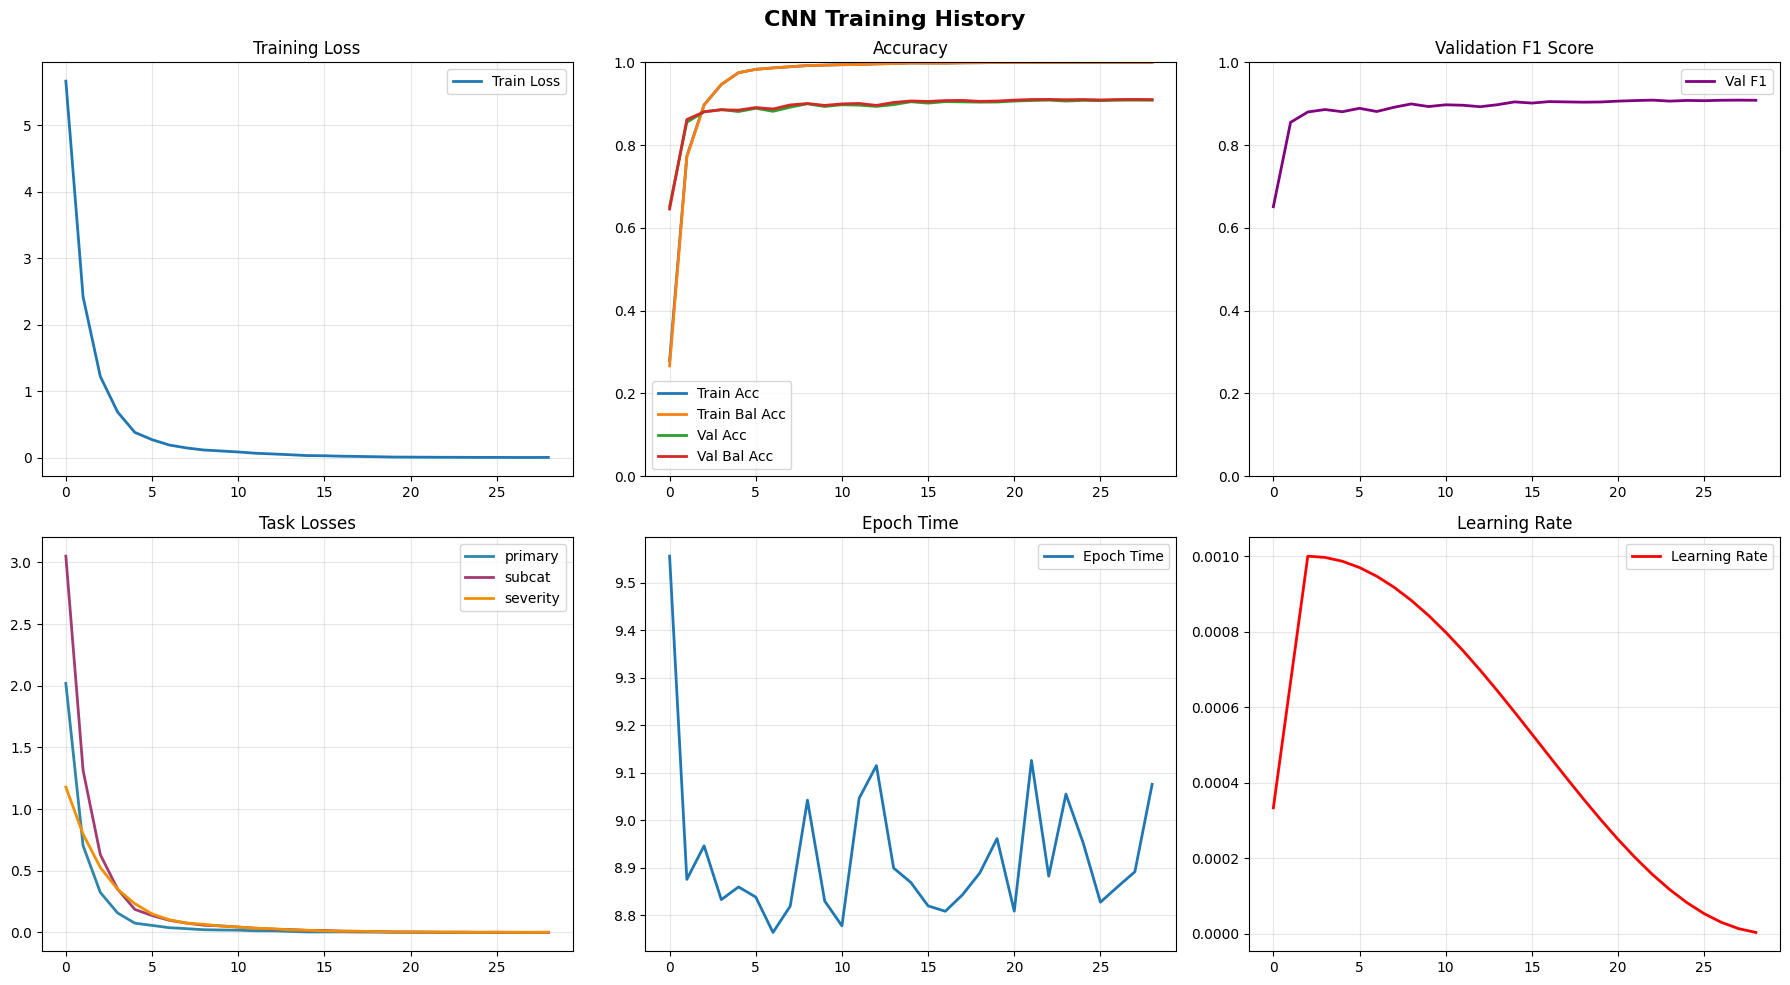

In [14]:
# ----------------------------------------------------------------------------
# CELL 14: TRAINING HISTORY VISUALIZATION
# ----------------------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Training loss
axes[0, 0].plot([h['loss'] for h in train_history], label='Train Loss', linewidth=2)
axes[0, 0].set_title('Training Loss')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

# Accuracy
axes[0, 1].plot([h['acc'] for h in train_history], label='Train Acc', linewidth=2)
axes[0, 1].plot([h['balanced_acc'] for h in train_history], label='Train Bal Acc', linewidth=2)
axes[0, 1].plot([h['val_acc'] for h in val_history], label='Val Acc', linewidth=2)
axes[0, 1].plot([h['val_bal_acc'] for h in val_history], label='Val Bal Acc', linewidth=2)
axes[0, 1].set_title('Accuracy')
axes[0, 1].set_ylim(0, 1)
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

# F1 Score
axes[0, 2].plot([h['val_f1'] for h in val_history], label='Val F1', linewidth=2, color='purple')
axes[0, 2].set_title('Validation F1 Score')
axes[0, 2].set_ylim(0, 1)
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

# Task losses
task_names = ['primary', 'subcat', 'severity']
colors = ['#2E86AB', '#A23B72', '#F18F01']
for task, color in zip(task_names, colors):
    values = [h['task_losses'][task] for h in train_history]
    axes[1, 0].plot(values, label=task, linewidth=2, color=color)
axes[1, 0].set_title('Task Losses')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

# Epoch time
axes[1, 1].plot([h['time'] for h in train_history], label='Epoch Time', linewidth=2)
axes[1, 1].set_title('Epoch Time')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

# Learning rate
axes[1, 2].plot([h['lr'] for h in train_history], label='Learning Rate', linewidth=2, color='red')
axes[1, 2].set_title('Learning Rate')
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

plt.suptitle(f'CNN Training History', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/training_history.png", dpi=300, bbox_inches='tight')
plt.show()

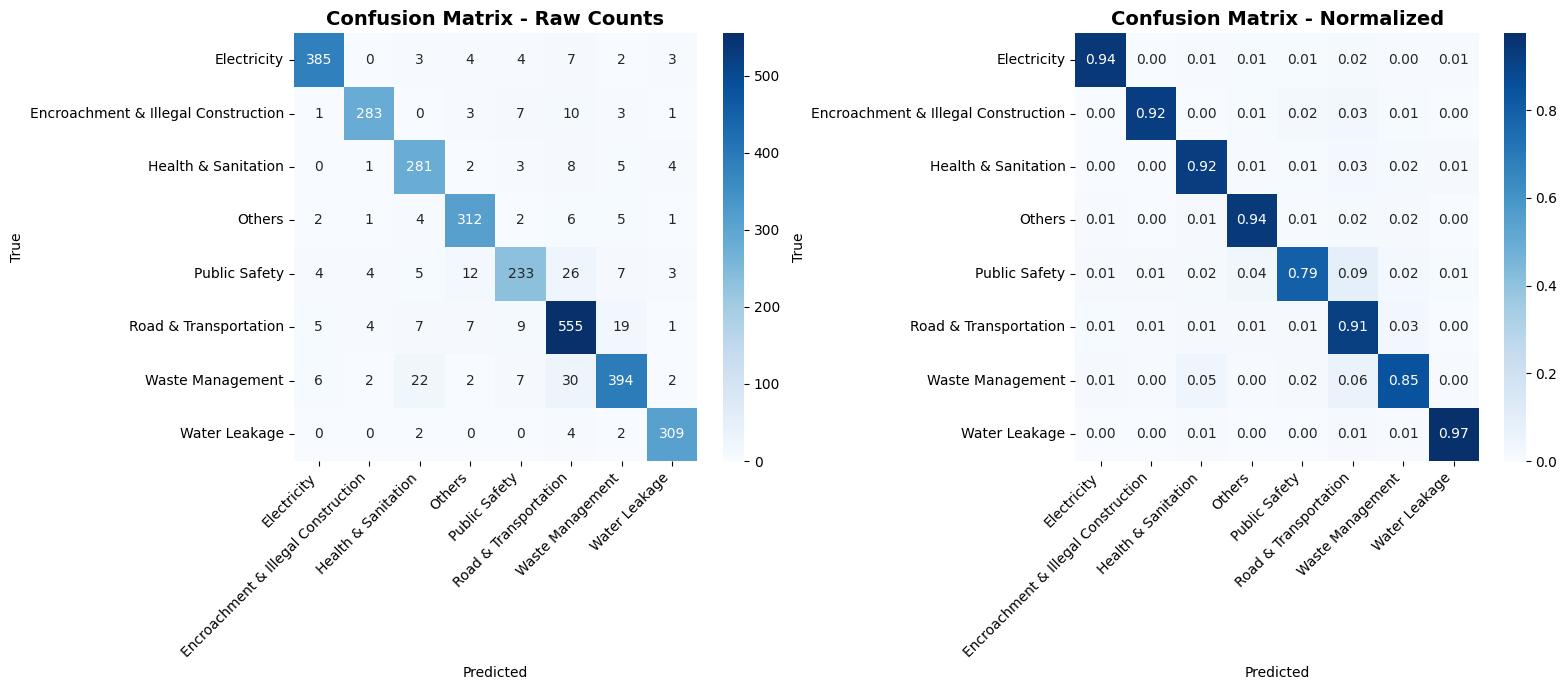

✅ Confusion matrix saved


In [15]:
# ----------------------------------------------------------------------------
# CELL 15: CONFUSION MATRIX
# ----------------------------------------------------------------------------

cm = confusion_matrix(test_labels, test_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_normalized = np.nan_to_num(cm_normalized)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
class_names = preprocessor.le_primary.classes_

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_title('Confusion Matrix - Raw Counts', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45, ha='right')

sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1])
axes[1].set_title('Confusion Matrix - Normalized', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45, ha='right')

plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrix_primary.png", dpi=300, bbox_inches='tight')
plt.show()
print("✅ Confusion matrix saved")


T-SNE EMBEDDING VISUALIZATION


Extracting embeddings: 100%|██████████| 24/24 [00:00<00:00, 43.20it/s]


Reducing dimensions with PCA...
Running t-SNE...


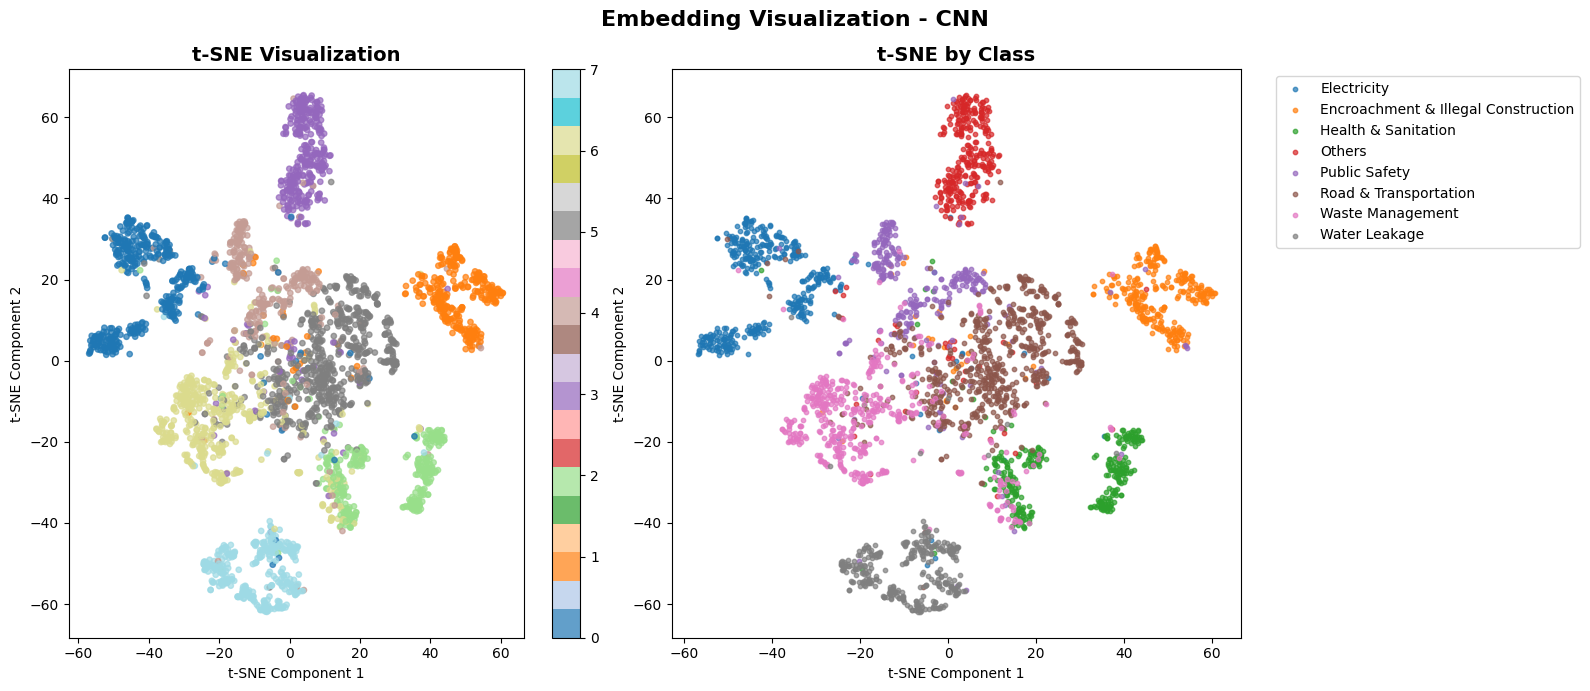

✅ t-SNE visualization saved


In [16]:
# ----------------------------------------------------------------------------
# CELL 16: T-SNE EMBEDDING VISUALIZATION
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("T-SNE EMBEDDING VISUALIZATION")
print("="*80)

model.eval()
embeddings, labels = [], []

with torch.no_grad():
    for batch in tqdm(test_loader, desc="Extracting embeddings"):
        input_ids = batch['input_ids'].to(Config.DEVICE)
        attention_mask = batch['attention_mask'].to(Config.DEVICE)
        emb = model.get_embeddings(input_ids, attention_mask)
        embeddings.append(emb.cpu().numpy())
        labels.extend(batch['primary'].cpu().numpy())

embeddings = np.vstack(embeddings)
labels = np.array(labels)

# PCA then t-SNE
print("Reducing dimensions with PCA...")
pca = PCA(n_components=50)
embeddings_pca = pca.fit_transform(embeddings)

print("Running t-SNE...")
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
embeddings_tsne = tsne.fit_transform(embeddings_pca)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# t-SNE scatter
scatter = axes[0].scatter(embeddings_tsne[:, 0], embeddings_tsne[:, 1], 
                          c=labels, cmap='tab20', s=15, alpha=0.7)
axes[0].set_title('t-SNE Visualization', fontsize=14, fontweight='bold')
axes[0].set_xlabel('t-SNE Component 1')
axes[0].set_ylabel('t-SNE Component 2')
plt.colorbar(scatter, ax=axes[0])

# By class
for i, class_name in enumerate(class_names):
    mask = labels == i
    if np.sum(mask) > 0:
        axes[1].scatter(embeddings_tsne[mask, 0], embeddings_tsne[mask, 1],
                       label=class_name, s=10, alpha=0.7)
axes[1].set_title('t-SNE by Class', fontsize=14, fontweight='bold')
axes[1].set_xlabel('t-SNE Component 1')
axes[1].set_ylabel('t-SNE Component 2')
axes[1].legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.suptitle(f'Embedding Visualization - CNN', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/tsne_embeddings.png", dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ t-SNE visualization saved")

In [17]:
# ----------------------------------------------------------------------------
# CELL 17: CLASSIFICATION REPORT
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("CLASSIFICATION REPORT")
print("="*80)

report = classification_report(test_labels, test_preds, target_names=class_names, digits=4)
print(report)

with open(f"{Config.RESULTS_DIR}/classification_report.txt", 'w') as f:
    f.write("Classification Report\n")
    f.write("="*60 + "\n")
    f.write(report)


CLASSIFICATION REPORT
                                     precision    recall  f1-score   support

                        Electricity     0.9553    0.9436    0.9494       408
Encroachment & Illegal Construction     0.9593    0.9188    0.9386       308
                Health & Sanitation     0.8673    0.9243    0.8949       304
                             Others     0.9123    0.9369    0.9244       333
                      Public Safety     0.8792    0.7925    0.8336       294
              Road & Transportation     0.8591    0.9143    0.8859       607
                   Waste Management     0.9016    0.8473    0.8736       465
                      Water Leakage     0.9537    0.9748    0.9641       317

                           accuracy                         0.9065      3036
                          macro avg     0.9110    0.9066    0.9081      3036
                       weighted avg     0.9072    0.9065    0.9061      3036



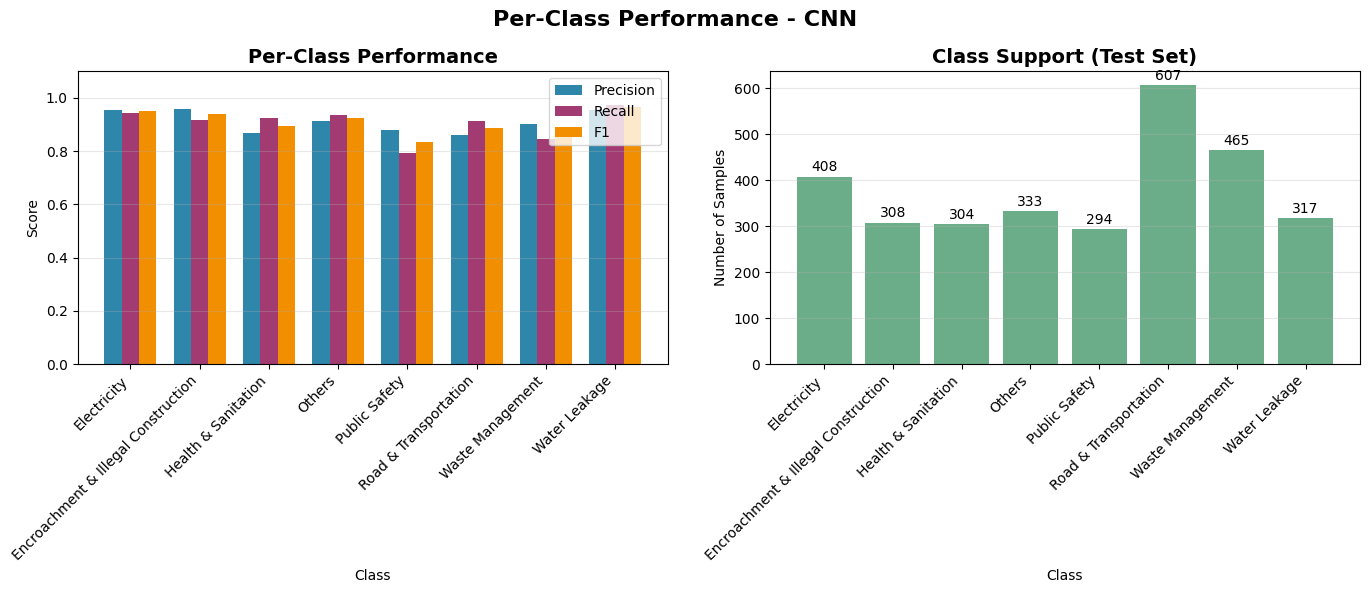

In [18]:
# ----------------------------------------------------------------------------
# CELL 18: PER-CLASS PERFORMANCE
# ----------------------------------------------------------------------------

from sklearn.metrics import precision_recall_fscore_support

precision, recall, f1, support = precision_recall_fscore_support(
    test_labels, test_preds, average=None, zero_division=0
)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

x = np.arange(len(class_names))
width = 0.25

axes[0].bar(x - width, precision, width, label='Precision', color='#2E86AB')
axes[0].bar(x, recall, width, label='Recall', color='#A23B72')
axes[0].bar(x + width, f1, width, label='F1', color='#F18F01')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Score')
axes[0].set_title('Per-Class Performance', fontsize=14, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(class_names, rotation=45, ha='right')
axes[0].set_ylim(0, 1.1)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

axes[1].bar(x, support, color='#2E8B57', alpha=0.7)
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Number of Samples')
axes[1].set_title('Class Support (Test Set)', fontsize=14, fontweight='bold')
axes[1].set_xticks(x)
axes[1].set_xticklabels(class_names, rotation=45, ha='right')
axes[1].grid(True, alpha=0.3, axis='y')

for i, s in enumerate(support):
    axes[1].text(i, s + 5, str(s), ha='center', va='bottom')

plt.suptitle(f'Per-Class Performance - CNN', 
            fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/per_class_performance.png", dpi=300, bbox_inches='tight')
plt.show()

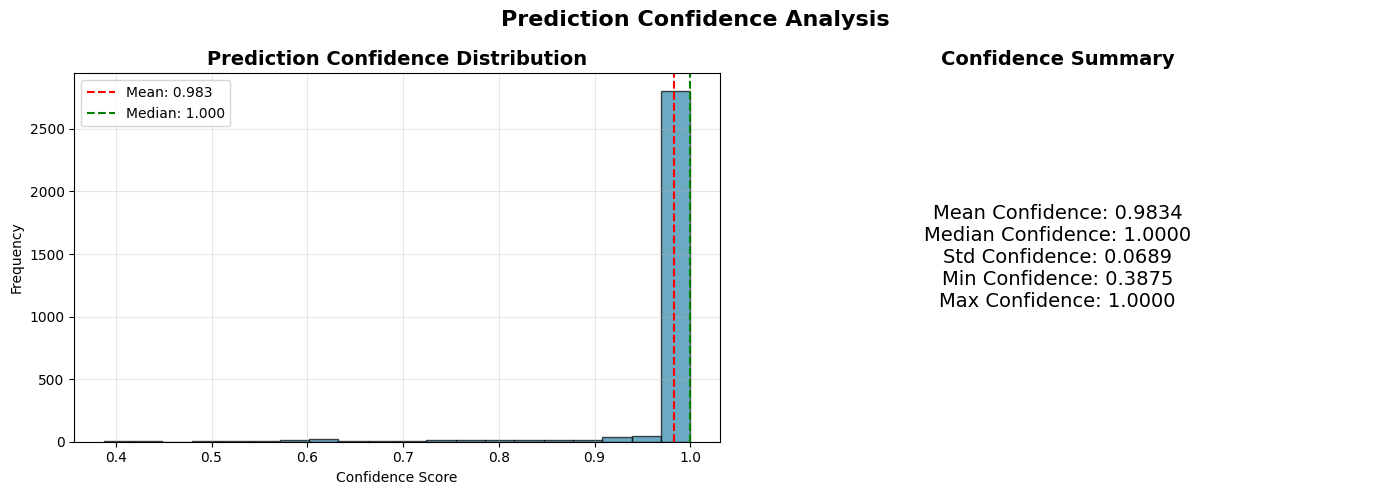

In [19]:
# ----------------------------------------------------------------------------
# CELL 19: CONFIDENCE ANALYSIS
# ----------------------------------------------------------------------------

confidences = test_metrics['confidences']

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(confidences, bins=20, edgecolor='black', alpha=0.7, color='#2E86AB')
axes[0].set_xlabel('Confidence Score')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Prediction Confidence Distribution', fontsize=14, fontweight='bold')
axes[0].axvline(np.mean(confidences), color='red', linestyle='--', 
               label=f'Mean: {np.mean(confidences):.3f}')
axes[0].axvline(np.median(confidences), color='green', linestyle='--', 
               label=f'Median: {np.median(confidences):.3f}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].text(0.5, 0.5, 
            f"Mean Confidence: {np.mean(confidences):.4f}\n"
            f"Median Confidence: {np.median(confidences):.4f}\n"
            f"Std Confidence: {np.std(confidences):.4f}\n"
            f"Min Confidence: {np.min(confidences):.4f}\n"
            f"Max Confidence: {np.max(confidences):.4f}",
            ha='center', va='center', fontsize=14,
            transform=axes[1].transAxes)
axes[1].set_title('Confidence Summary', fontsize=14, fontweight='bold')
axes[1].axis('off')

plt.suptitle('Prediction Confidence Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confidence_analysis.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
# ----------------------------------------------------------------------------
# CELL 20: SAVE MODEL, VOCABULARY AND ENCODERS
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print("SAVING MODEL, VOCABULARY AND ENCODERS")
print("="*80)

torch.save({
    'model_state_dict': model.state_dict(),
    'model_config': model.config_dict,
    'n_primary': model.n_primary,
    'n_subcat': model.n_subcat,
    'n_severity': model.n_severity,
    'hidden_size': model.hidden_size,
    'max_length': Config.MAX_LENGTH,
    'base_model': Config.BASE_MODEL
}, f"{Config.MODEL_DIR}/cnn_model.pt")

with open(f"{Config.MODEL_DIR}/vocab.pkl", 'wb') as f:
    pickle.dump(vocab, f)
with open(f"{Config.MODEL_DIR}/le_primary.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_primary, f)
with open(f"{Config.MODEL_DIR}/le_subcat.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_subcat, f)
with open(f"{Config.MODEL_DIR}/le_severity.pkl", 'wb') as f:
    pickle.dump(preprocessor.le_severity, f)

print(f"✅ Model saved to: {Config.MODEL_DIR}/cnn_model.pt")
print(f"✅ Vocabulary saved ({len(vocab)} tokens)")
print(f"✅ Label encoders saved to: {Config.MODEL_DIR}/le_*.pkl")



SAVING MODEL, VOCABULARY AND ENCODERS
✅ Model saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\models/cnn_model.pt
✅ Vocabulary saved (29763 tokens)
✅ Label encoders saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\models/le_*.pkl


In [21]:
# ----------------------------------------------------------------------------
# CELL 21: COMPLETE SUMMARY
# ----------------------------------------------------------------------------

print("\n" + "="*80)
print(f"CNN COMPLETE SUMMARY")
print("="*80)

print("\n1. DATASET STATISTICS:")
print(f"   Training: {len(train_df)}, Validation: {len(dev_df)}, Test: {len(test_df)}")
print(f"   Primary Categories: {len(preprocessor.le_primary.classes_)}")
print(f"   Subcategories: {len(preprocessor.le_subcat.classes_)}")
print(f"   Severity Levels: {len(preprocessor.le_severity.classes_)}")

print("\n2. MODEL STATISTICS:")
print(f"   Total Parameters: {sum(p.numel() for p in model.parameters()):,}")
print(f"   Hidden Size: {model.hidden_size}")
print(f"   Dropout: {Config.DROPOUT}")

print("\n3. TEST PERFORMANCE:")
for metric, value in test_metrics.items():
    if not isinstance(value, np.ndarray):
        print(f"   {metric}: {value:.4f}")

print(f"\n4. BEST VALIDATION:")
print(f"   F1: {best_val_f1:.4f}, Balanced Accuracy: {best_val_balanced_acc:.4f}")

print(f"\n5. TRAINING TIME:")
print(f"   Total: {total_time/60:.1f} minutes")

print("\n" + "="*80)
print("EXPERIMENT COMPLETED SUCCESSFULLY!")
print("="*80)

print(f"\n✅ All results saved to: {Config.BASE_DIR}")
print(f"📁 Results: {Config.RESULTS_DIR}")
print(f"📁 Visualizations: {Config.VISUALIZATION_DIR}")
print(f"📁 Models: {Config.MODEL_DIR}")


CNN COMPLETE SUMMARY

1. DATASET STATISTICS:
   Training: 14165, Validation: 3035, Test: 3036
   Primary Categories: 8
   Subcategories: 24
   Severity Levels: 3

2. MODEL STATISTICS:
   Total Parameters: 9,748,647
   Hidden Size: 512
   Dropout: 0.3

3. TEST PERFORMANCE:
   accuracy: 0.9065
   balanced_accuracy: 0.9066
   f1_macro: 0.9081
   f1_weighted: 0.9061
   precision: 0.9072
   recall: 0.9065
   cohen_kappa: 0.8919
   mcc: 0.8921

4. BEST VALIDATION:
   F1: 0.9087, Balanced Accuracy: 0.9105

5. TRAINING TIME:
   Total: 4.4 minutes

EXPERIMENT COMPLETED SUCCESSFULLY!

✅ All results saved to: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common
📁 Results: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\results
📁 Visualizations: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\visualizations
📁 Models: C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\models


In [22]:
# ----------------------------------------------------------------------------
# CELL 22: EVALUATION ENGINE (common / per-language / per-class)
# ----------------------------------------------------------------------------
# The model is trained on the COMMON text (title + English + Hindi + Hinglish).
# It is then evaluated on four versions of the same test set:
#   Common   - the combined text (what the model was trained on)
#   English  - input text = ONLY the English column
#   Hindi    - input text = ONLY the Hindi (Devanagari) column
#   Hinglish - input text = ONLY the Hinglish column
# For every version we report all three tasks, overall and PER CLASS.

TASKS = [('primary', 'Primary'), ('subcat', 'Subcategory'), ('severity', 'Severity')]
CLASS_NAMES = {
    'primary': list(preprocessor.le_primary.classes_),
    'subcat': list(preprocessor.le_subcat.classes_),
    'severity': list(preprocessor.le_severity.classes_),
}
SETTINGS = ['Common'] + list(Config.LANGUAGE_COLUMNS.keys())


def get_predictions(model, dataloader, device):
    """Predictions and labels for all three tasks (+ primary-task confidence)."""
    model.eval()
    out = {k: {'preds': [], 'labels': []} for k, _ in TASKS}
    conf = []
    with torch.no_grad():
        for batch in tqdm(dataloader, desc="Predicting", leave=False):
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            logits = dict(zip(['primary', 'subcat', 'severity'], model(input_ids, attention_mask)))
            for key, _ in TASKS:
                out[key]['preds'].extend(torch.argmax(logits[key], dim=1).cpu().numpy())
                out[key]['labels'].extend(batch[key].cpu().numpy())
            conf.extend(torch.softmax(logits['primary'].float(), dim=1).max(dim=1)[0].cpu().numpy())
    for key in out:
        out[key]['preds'] = np.array(out[key]['preds'])
        out[key]['labels'] = np.array(out[key]['labels'])
    out['confidence'] = np.array(conf)
    return out


def compute_metrics(y_true, y_pred):
    """Overall metrics for one task."""
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Balanced_Acc': balanced_accuracy_score(y_true, y_pred),
        'F1-Macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'F1-Weighted': f1_score(y_true, y_pred, average='weighted', zero_division=0),
        'Precision': precision_score(y_true, y_pred, average='weighted', zero_division=0),
        'Recall': recall_score(y_true, y_pred, average='weighted', zero_division=0),
        'Cohen_Kappa': cohen_kappa_score(y_true, y_pred),
        'MCC': matthews_corrcoef(y_true, y_pred),
    }


def per_class_metrics(y_true, y_pred, class_names):
    """Precision / recall / F1 / support for every class (classes absent from y_true get 0)."""
    p, r, f, s = precision_recall_fscore_support(
        y_true, y_pred, labels=list(range(len(class_names))), zero_division=0)
    return pd.DataFrame({'Class': class_names, 'Precision': p, 'Recall': r, 'F1': f, 'Support': s})


def build_language_df(df, col):
    """Rows of the preprocessed dataframe whose `col` text is non-empty."""
    if col not in df.columns:
        raise KeyError(f"Column '{col}' not in dataframe. Available: {list(df.columns)}")
    keep = df[col].fillna('').astype(str).str.strip() != ''
    return df[keep].reset_index(drop=True)


def devanagari_fraction(texts):
    """Share of alphabetic characters that are Devanagari (script sanity check)."""
    dev = alpha = 0
    for t in texts:
        for ch in t:
            if ch.isalpha():
                alpha += 1
                if '\u0900' <= ch <= '\u097F':
                    dev += 1
    return dev / max(alpha, 1)


def oov_rate(texts, vocab):
    """Share of tokens that map to <unk>."""
    total = unk = 0
    for t in texts:
        for tok in Vocabulary.tokenize(t):
            total += 1
            unk += tok not in vocab.word2idx
    return unk / max(total, 1)


print("✅ Evaluation engine defined")


✅ Evaluation engine defined


In [23]:
# ----------------------------------------------------------------------------
# CELL 23: RUN EVALUATION - COMMON + ENGLISH + HINDI + HINGLISH
# ----------------------------------------------------------------------------

# Use the best checkpoint
checkpoint_path = f"{Config.MODEL_DIR}/best_cnn_model.pt"
if os.path.exists(checkpoint_path):
    checkpoint = torch.load(checkpoint_path, map_location=Config.DEVICE, weights_only=False)
    model.load_state_dict(checkpoint["model_state_dict"])
    print("✅ Loaded best model")
model.eval()

print("\n" + "=" * 80)
print("EVALUATING: COMMON TEXT AND EACH LANGUAGE SEPARATELY")
print("=" * 80)

results = {}   # results[setting] = {'n': int, 'tasks': {task: {...}}, 'confidence': array}

for setting in SETTINGS:
    if setting == 'Common':
        text_col, eval_df = 'text', test_df
        print(f"\n--- Common (title + English + Hindi + Hinglish): {len(eval_df)} samples ---")
    else:
        text_col = Config.LANGUAGE_COLUMNS[setting]
        eval_df = build_language_df(test_df, text_col)
        if len(eval_df) == 0:
            print(f"⚠️ No non-empty text in '{text_col}'. Skipping {setting}.")
            continue
        texts = eval_df[text_col].astype(str).tolist()
        dev_frac, oov = devanagari_fraction(texts), oov_rate(texts, vocab)
        print(f"\n--- {setting}: {len(eval_df)} samples | Devanagari chars: {dev_frac:.1%} | OOV tokens: {oov:.1%} ---")
        print(f"    example: {texts[0][:100]}")
        if setting == 'Hindi' and dev_frac < 0.5:
            print("    ⚠️ 'Hindi' column is mostly NOT Devanagari - check the column mapping.")
        if setting in ('English', 'Hinglish') and dev_frac > 0.1:
            print(f"    ⚠️ '{setting}' column contains Devanagari text - check the column mapping.")

    ds = PreTokenizedDataset(eval_df, vocab, Config.MAX_LENGTH, text_col=text_col)
    loader = DataLoader(ds, batch_size=Config.BATCH_SIZE * 2, shuffle=False, num_workers=0)
    preds = get_predictions(model, loader, Config.DEVICE)

    results[setting] = {'n': len(eval_df), 'tasks': {}, 'confidence': preds['confidence']}
    for key, _ in TASKS:
        y_true, y_pred = preds[key]['labels'], preds[key]['preds']
        results[setting]['tasks'][key] = {
            'metrics': compute_metrics(y_true, y_pred),
            'per_class': per_class_metrics(y_true, y_pred, CLASS_NAMES[key]),
            'y_true': y_true,
            'y_pred': y_pred,
        }
    m = results[setting]['tasks']
    print(f"    Primary  F1-Macro: {m['primary']['metrics']['F1-Macro']:.4f} | "
          f"Subcat F1-Macro: {m['subcat']['metrics']['F1-Macro']:.4f} | "
          f"Severity F1-Macro: {m['severity']['metrics']['F1-Macro']:.4f}")

SETTINGS = [s for s in SETTINGS if s in results]
print("\n✅ Evaluation finished for:", SETTINGS)


✅ Loaded best model

EVALUATING: COMMON TEXT AND EACH LANGUAGE SEPARATELY

--- Common (title + English + Hindi + Hinglish): 3036 samples ---
Pre-encoding dataset (text column: 'text')...
✅ Pre-encoded 3036 samples


    Primary  F1-Macro: 0.9081 | Subcat F1-Macro: 0.7997 | Severity F1-Macro: 0.8514

--- English: 3036 samples | Devanagari chars: 0.0% | OOV tokens: 1.4% ---
    example: The Tender Sure footpath of St. Marks Road has been dug up by Sobha Builders. Please ensure that the
Pre-encoding dataset (text column: 'text_en')...
✅ Pre-encoded 3036 samples


    Primary  F1-Macro: 0.8500 | Subcat F1-Macro: 0.7079 | Severity F1-Macro: 0.8007

--- Hindi: 3036 samples | Devanagari chars: 99.8% | OOV tokens: 1.2% ---
    example: सेंट मार्क्स रोड के टेंडर श्योर फुटपाथ को शोभा बिल्डर्स ने खोद दिया है। कृपया सुनिश्चित करें कि अपूर
Pre-encoding dataset (text column: 'Hindi')...
✅ Pre-encoded 3036 samples


    Primary  F1-Macro: 0.6491 | Subcat F1-Macro: 0.4701 | Severity F1-Macro: 0.7460

--- Hinglish: 3036 samples | Devanagari chars: 0.2% | OOV tokens: 3.9% ---
    example: Saint Marks Road ke Tender Sure footpath ko Sobha Builders ne khod diya hai. Kripya sunishchit karei
Pre-encoding dataset (text column: 'Hinglish')...
✅ Pre-encoded 3036 samples


    Primary  F1-Macro: 0.6027 | Subcat F1-Macro: 0.4247 | Severity F1-Macro: 0.4966

✅ Evaluation finished for: ['Common', 'English', 'Hindi', 'Hinglish']


In [24]:
# ----------------------------------------------------------------------------
# CELL 24: RESULT TABLES (overall, language-wise, task-wise)
# ----------------------------------------------------------------------------

metric_cols = ['Accuracy', 'Balanced_Acc', 'F1-Macro', 'F1-Weighted', 'Precision', 'Recall', 'Cohen_Kappa', 'MCC']
task_name = dict(TASKS)

# --- Overall: every setting x every task ---
rows = []
for setting in SETTINGS:
    for key, name in TASKS:
        rows.append({'Model': 'CNN', 'Setting': setting, 'Task': name, 'Samples': results[setting]['n'],
                     **results[setting]['tasks'][key]['metrics']})
df_overall = pd.DataFrame(rows)

print("=" * 100)
print("TABLE A: OVERALL PERFORMANCE - COMMON AND EACH LANGUAGE, ALL TASKS")
print("=" * 100)
print(df_overall.round(4).to_string(index=False))
df_overall.to_csv(f"{Config.RESULTS_DIR}/table_overall_language_task.csv", index=False)

# --- Table 14: language-wise (primary category) ---
df_table14 = df_overall[df_overall['Task'] == 'Primary'].drop(columns='Task')
print("\n" + "=" * 100)
print("TABLE 14: LANGUAGE-WISE PERFORMANCE - PRIMARY CATEGORY")
print("=" * 100)
print(df_table14.round(4).to_string(index=False))
df_table14.to_csv(f"{Config.RESULTS_DIR}/table14_language_performance.csv", index=False)

# --- Table 15: task-wise on the common text ---
df_table15 = df_overall[df_overall['Setting'] == 'Common'].drop(columns='Setting')
print("\n" + "=" * 100)
print("TABLE 15: TASK-WISE PERFORMANCE ON THE COMMON TEXT")
print("=" * 100)
print(df_table15.round(4).to_string(index=False))
df_table15.to_csv(f"{Config.RESULTS_DIR}/table15_category_performance.csv", index=False)

# --- Compact view: Macro-F1 / Accuracy by setting x task ---
for metric in ['F1-Macro', 'Accuracy']:
    pivot = df_overall.pivot(index='Setting', columns='Task', values=metric).loc[SETTINGS, [n for _, n in TASKS]]
    print(f"\n{metric} by setting and task:")
    print(pivot.round(4).to_string())

# --- LaTeX ---
for fname, frame, cap, lab in [
    ('table_overall_language_task.tex', df_overall, 'CNN performance by language and task', 'tab:cnn_language_task'),
    ('table14_language_performance.tex', df_table14, 'Language-wise performance (primary category) of CNN', 'tab:cnn_language'),
    ('table15_category_performance.tex', df_table15, 'Task-wise performance of CNN on the common text', 'tab:cnn_task'),
]:
    with open(f"{Config.RESULTS_DIR}/{fname}", "w") as f:
        f.write(frame.to_latex(index=False, float_format="%.4f", caption=cap, label=lab))

print(f"\n✅ Overall tables saved to {Config.RESULTS_DIR}")


TABLE A: OVERALL PERFORMANCE - COMMON AND EACH LANGUAGE, ALL TASKS
Model  Setting        Task  Samples  Accuracy  Balanced_Acc  F1-Macro  F1-Weighted  Precision  Recall  Cohen_Kappa    MCC
  CNN   Common     Primary     3036    0.9065        0.9066    0.9081       0.9061     0.9072  0.9065       0.8919 0.8921
  CNN   Common Subcategory     3036    0.8152        0.7891    0.7997       0.8150     0.8170  0.8152       0.8014 0.8016
  CNN   Common    Severity     3036    0.8554        0.8523    0.8514       0.8556     0.8559  0.8554       0.7799 0.7800
  CNN  English     Primary     3036    0.8501        0.8458    0.8500       0.8501     0.8549  0.8501       0.8266 0.8272
  CNN  English Subcategory     3036    0.7312        0.6872    0.7079       0.7284     0.7433  0.7312       0.7087 0.7113
  CNN  English    Severity     3036    0.8103        0.7988    0.8007       0.8064     0.8080  0.8103       0.7084 0.7111
  CNN    Hindi     Primary     3036    0.6555        0.6432    0.6491       0.6

In [25]:
# ----------------------------------------------------------------------------
# CELL 25: PER-CLASS (PER-CATEGORY) RESULTS FOR EVERY SETTING
# ----------------------------------------------------------------------------

long_rows = []
for setting in SETTINGS:
    for key, name in TASKS:
        pc = results[setting]['tasks'][key]['per_class'].copy()
        pc.insert(0, 'Task', name)
        pc.insert(0, 'Setting', setting)
        long_rows.append(pc)
df_per_class = pd.concat(long_rows, ignore_index=True)
df_per_class.to_csv(f"{Config.RESULTS_DIR}/per_class_metrics_all.csv", index=False)

pivots = {}   # pivots[task_key] = class x setting table of F1
for key, name in TASKS:
    sub = df_per_class[df_per_class['Task'] == name]
    f1_pivot = sub.pivot(index='Class', columns='Setting', values='F1').loc[CLASS_NAMES[key], SETTINGS]
    pivots[key] = f1_pivot

    print("\n" + "=" * 100)
    print(f"PER-CLASS F1 - {name.upper()} (rows = classes, columns = Common / English / Hindi / Hinglish)")
    print("=" * 100)
    print(f1_pivot.round(4).to_string())
    print("\nClass support (Common test set):")
    print(sub[sub['Setting'] == 'Common'].set_index('Class')['Support'].loc[CLASS_NAMES[key]].to_string())

    f1_pivot.to_csv(f"{Config.RESULTS_DIR}/per_class_f1_{key}.csv")

    # Full precision / recall / F1 / support, one wide table per task
    wide = sub.pivot(index='Class', columns='Setting', values=['Precision', 'Recall', 'F1', 'Support'])
    wide = wide.reindex(CLASS_NAMES[key])
    wide = wide.reorder_levels([1, 0], axis=1)[[(s, m) for s in SETTINGS for m in ['Precision', 'Recall', 'F1', 'Support']]]
    wide.to_csv(f"{Config.RESULTS_DIR}/per_class_full_{key}.csv")

# --- Full sklearn classification reports for every setting and task ---
for setting in SETTINGS:
    for key, name in TASKS:
        t = results[setting]['tasks'][key]
        report = classification_report(
            t['y_true'], t['y_pred'], labels=list(range(len(CLASS_NAMES[key]))),
            target_names=CLASS_NAMES[key], digits=4, zero_division=0)
        with open(f"{Config.RESULTS_DIR}/classification_report_{setting.lower()}_{key}.txt", "w") as f:
            f.write(f"CNN classification report - {setting} - {name}\n{'=' * 60}\n{report}")

print("\n" + "=" * 100)
print("CLASSIFICATION REPORT - PRIMARY CATEGORY, EACH SETTING")
print("=" * 100)
for setting in SETTINGS:
    t = results[setting]['tasks']['primary']
    print(f"\n### {setting} ({results[setting]['n']} samples)")
    print(classification_report(t['y_true'], t['y_pred'], labels=list(range(len(CLASS_NAMES['primary']))),
                                target_names=CLASS_NAMES['primary'], digits=4, zero_division=0))

print(f"\n✅ Per-class tables and reports saved to {Config.RESULTS_DIR}")



PER-CLASS F1 - PRIMARY (rows = classes, columns = Common / English / Hindi / Hinglish)
Setting                              Common  English   Hindi  Hinglish
Class                                                                 
Electricity                          0.9494   0.9137  0.7257    0.7656
Encroachment & Illegal Construction  0.9386   0.8659  0.8514    0.6208
Health & Sanitation                  0.8949   0.8300  0.6755    0.6523
Others                               0.9244   0.8841  0.5959    0.5595
Public Safety                        0.8336   0.7540  0.4813    0.4587
Road & Transportation                0.8859   0.8374  0.6458    0.6192
Waste Management                     0.8736   0.8190  0.6095    0.5098
Water Leakage                        0.9641   0.8959  0.6078    0.6357

Class support (Common test set):
Class
Electricity                            408
Encroachment & Illegal Construction    308
Health & Sanitation                    304
Others                           

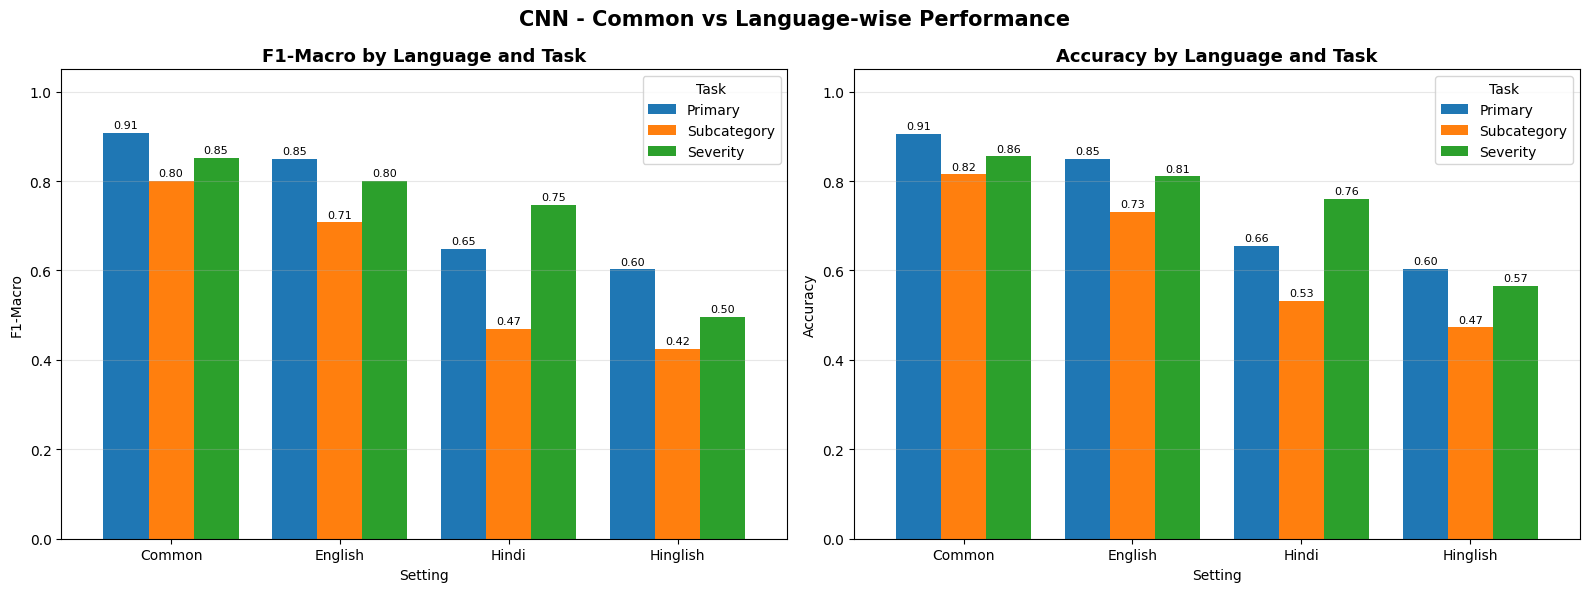

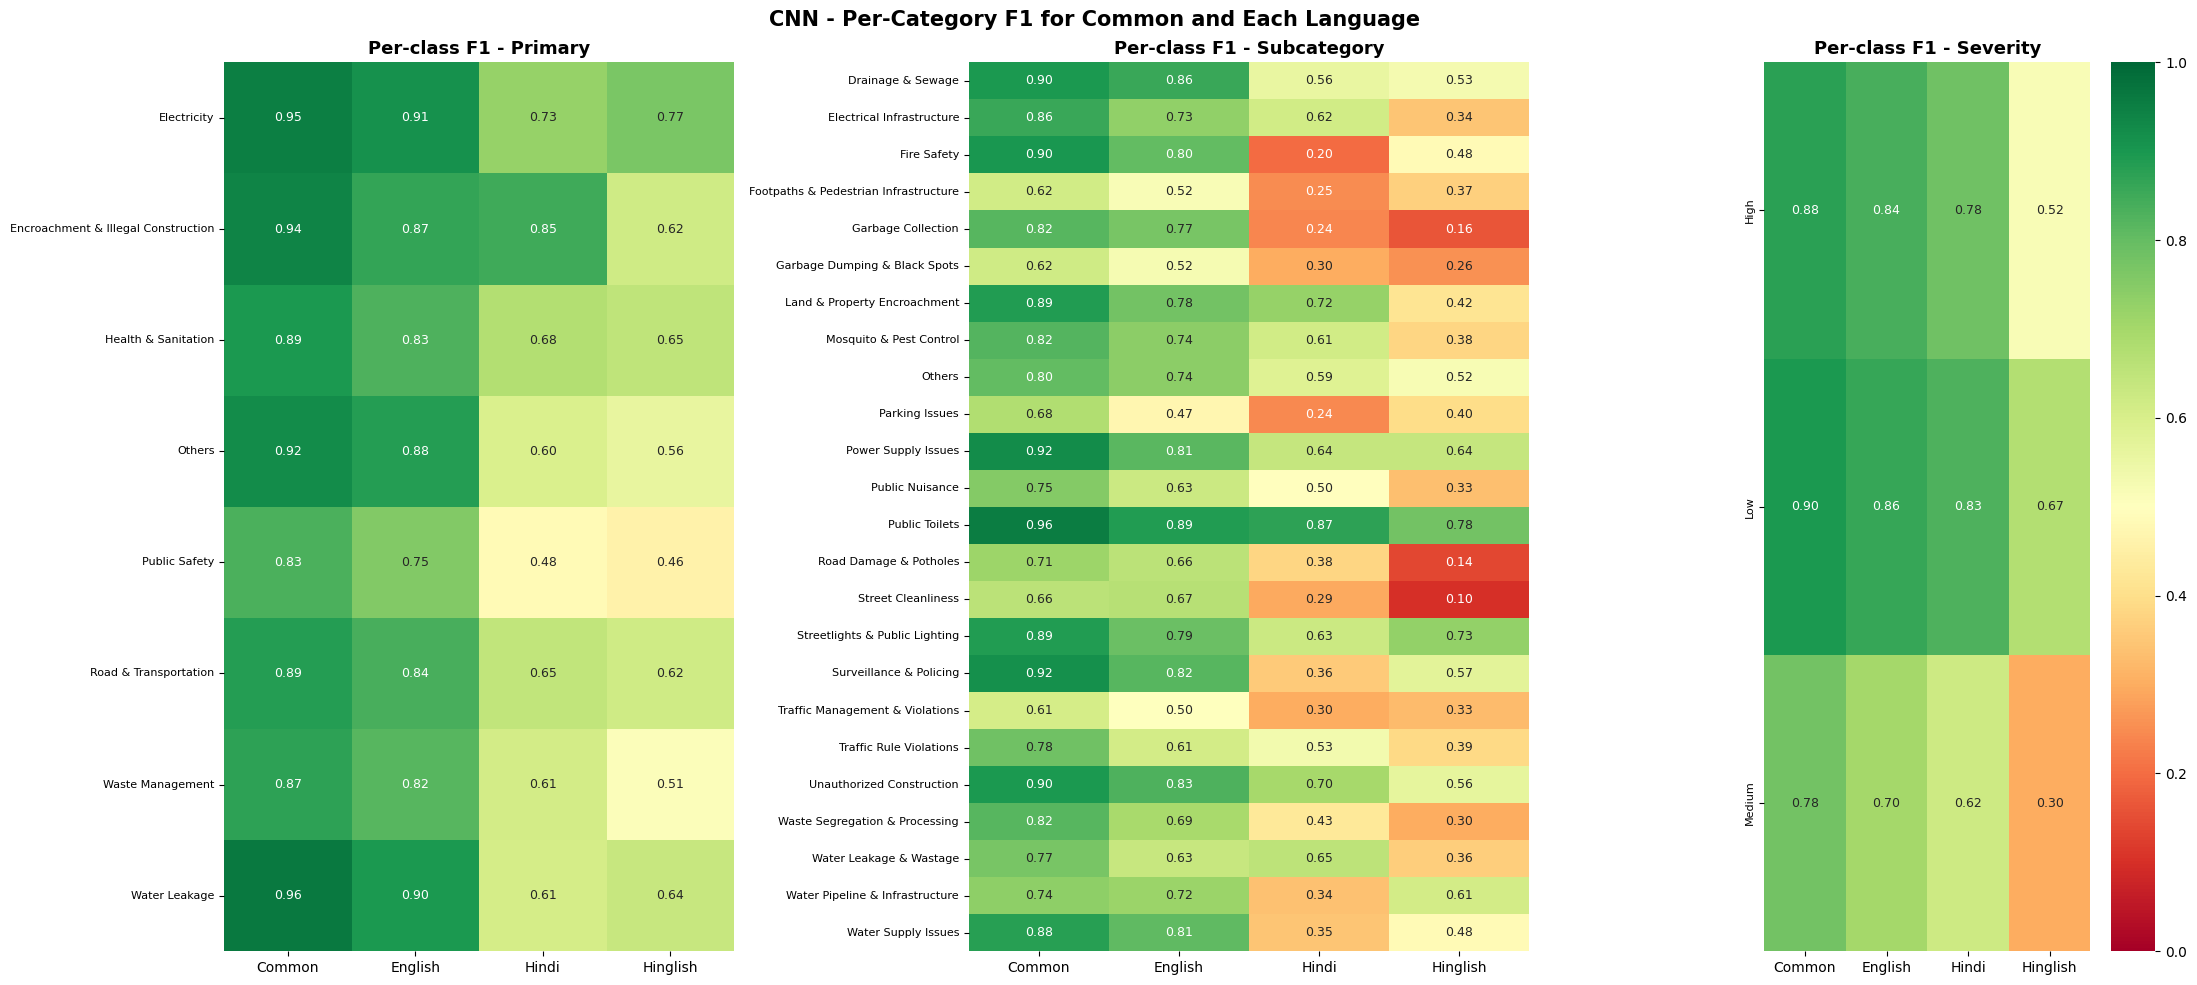

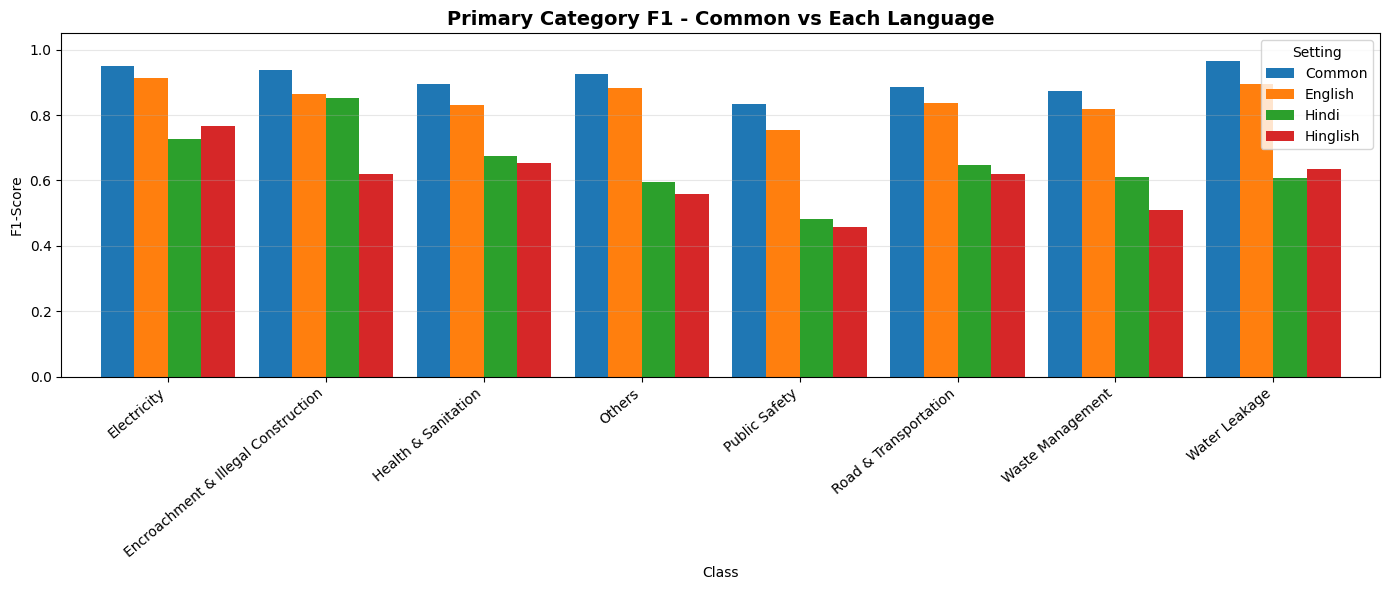

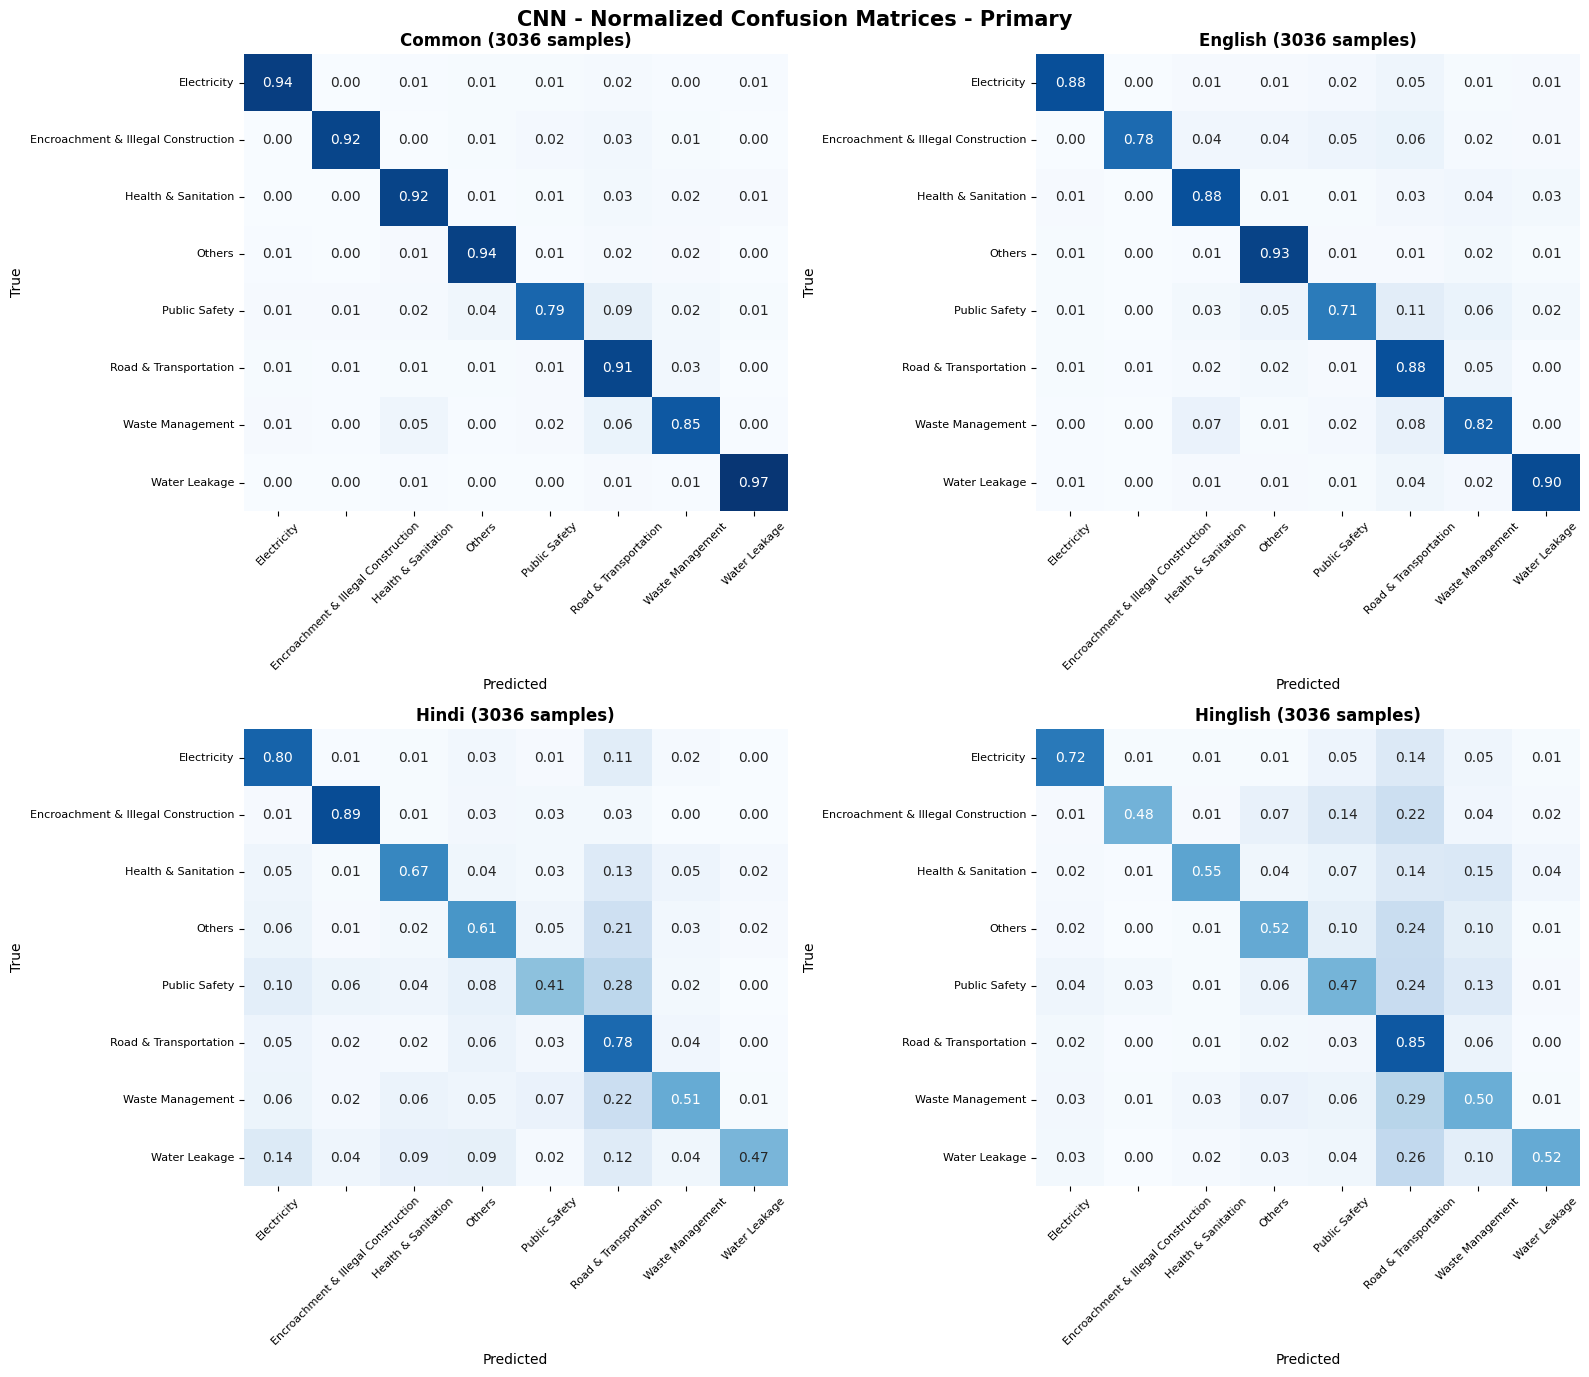

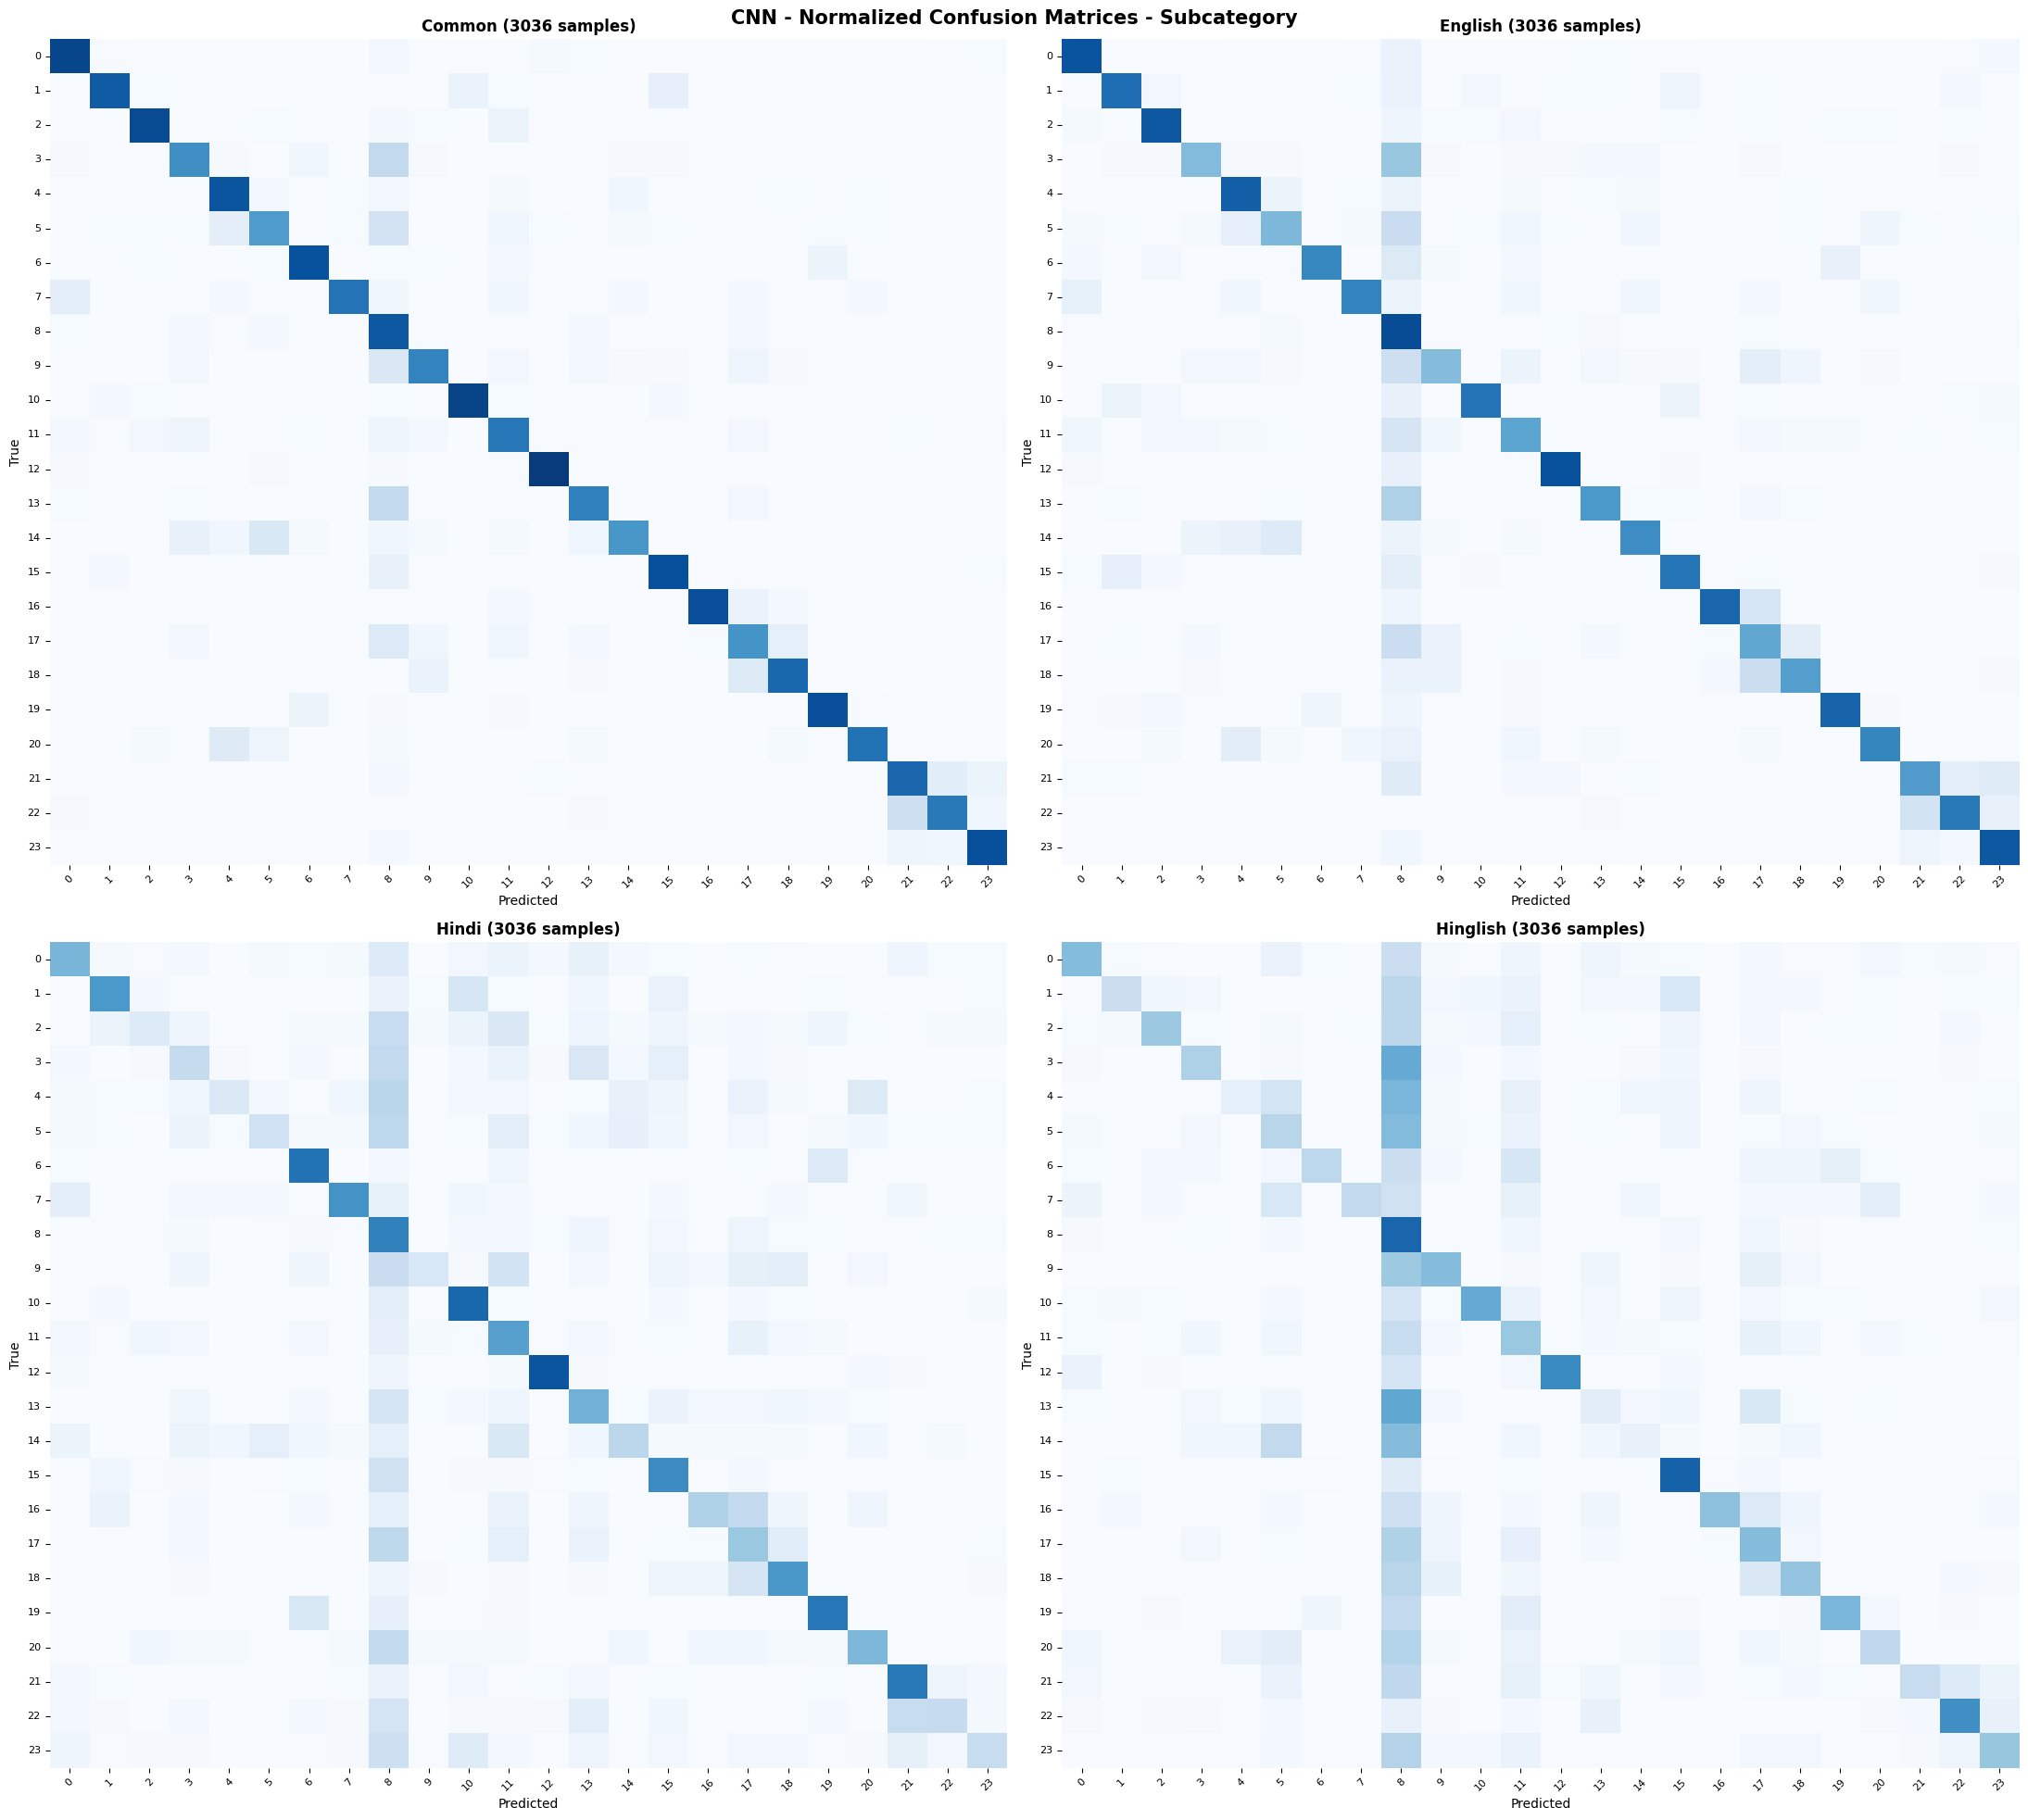

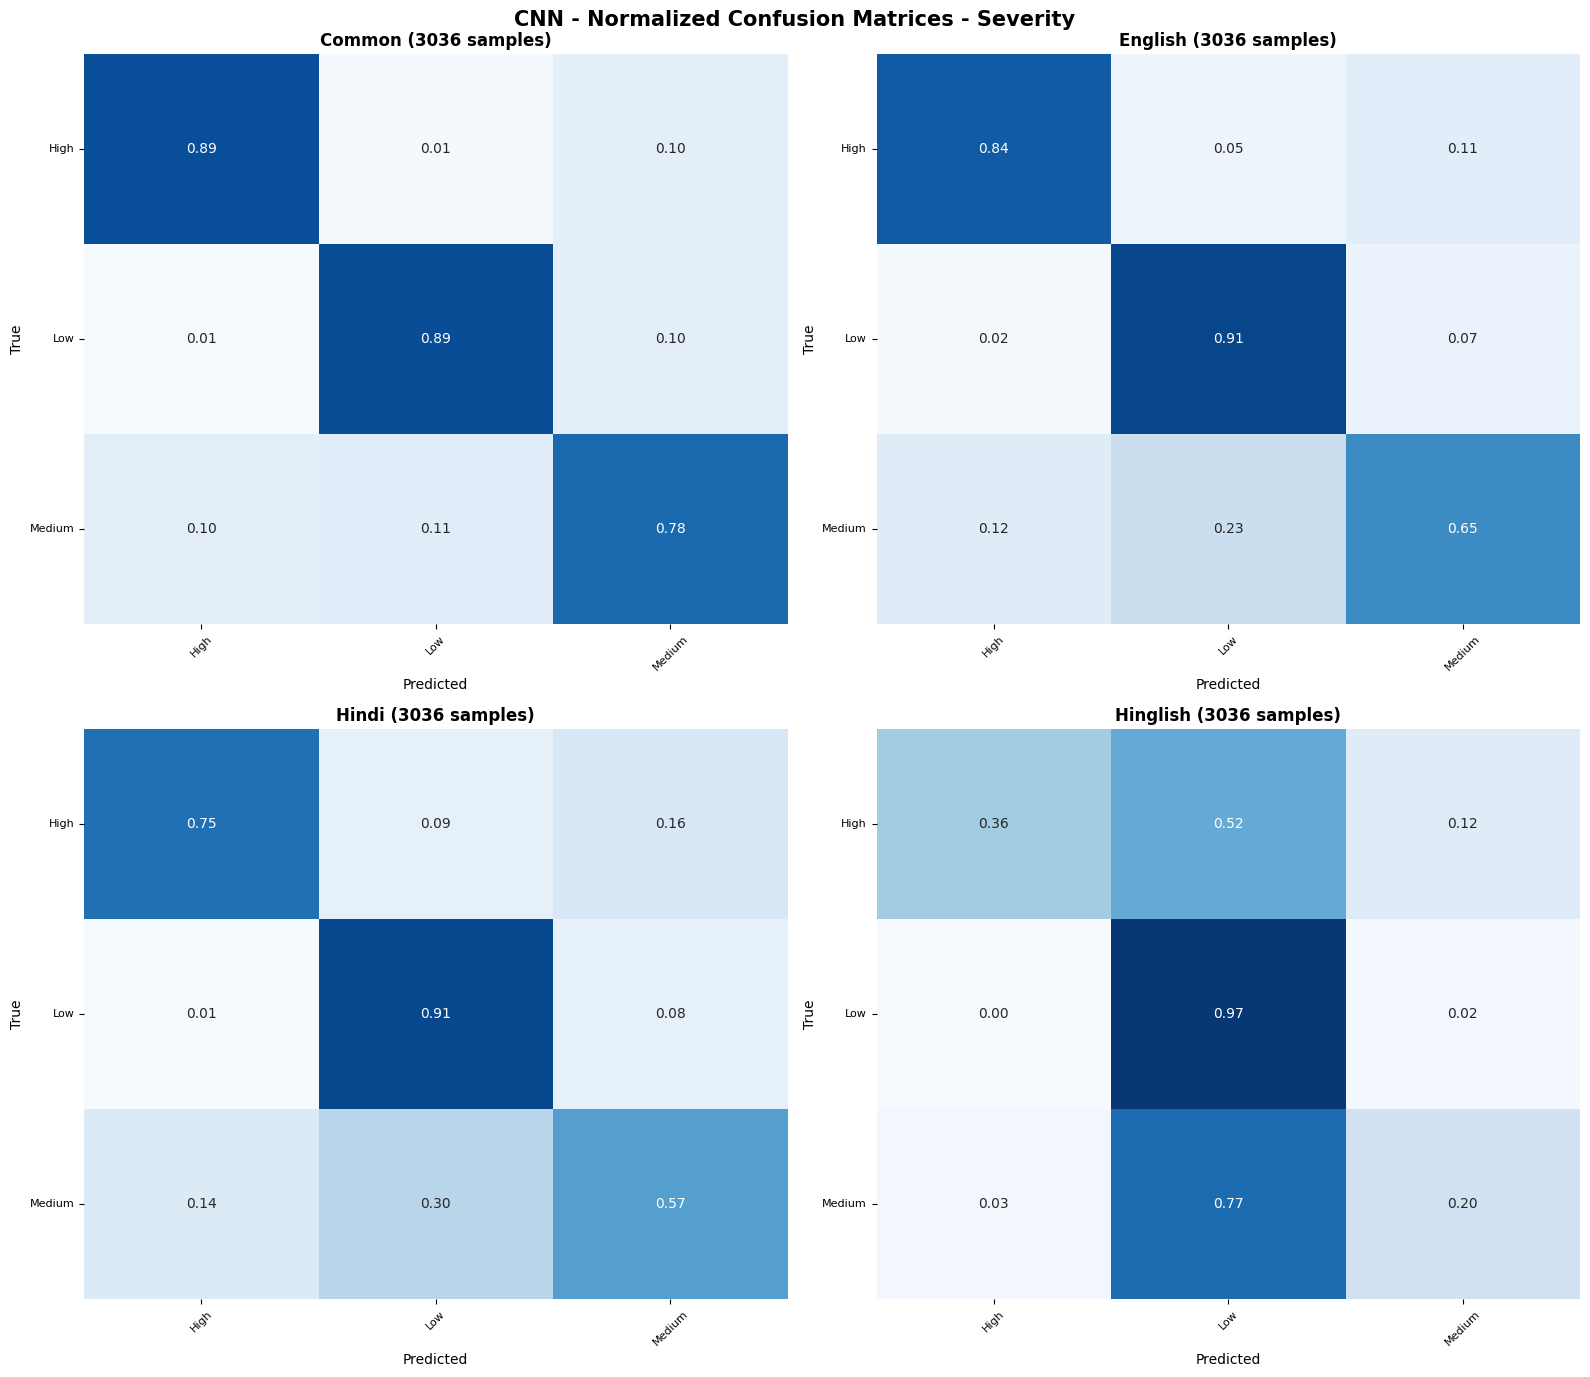

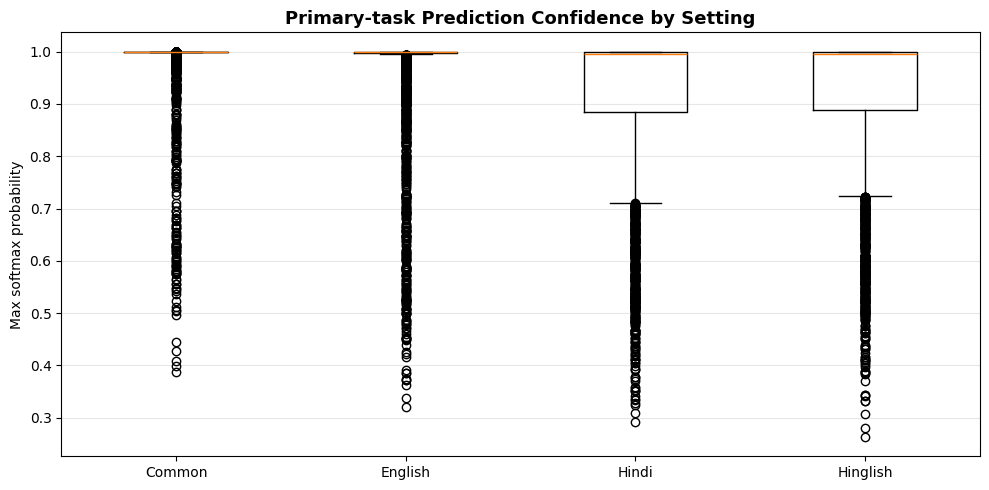

✅ Visualizations saved to C:\Users\CH.SC.U4CSE23160\Final_Year_Project\cnn_results_common\visualizations


In [26]:
# ----------------------------------------------------------------------------
# CELL 26: VISUALIZATIONS - LANGUAGE x TASK x CLASS
# ----------------------------------------------------------------------------

# 1) Overall Macro-F1 and Accuracy by setting and task
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, metric in zip(axes, ['F1-Macro', 'Accuracy']):
    pv = df_overall.pivot(index='Setting', columns='Task', values=metric).loc[SETTINGS, [n for _, n in TASKS]]
    pv.plot(kind='bar', ax=ax, width=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel(metric)
    ax.set_title(f'{metric} by Language and Task', fontsize=13, fontweight='bold')
    ax.grid(True, alpha=0.3, axis='y')
    ax.tick_params(axis='x', rotation=0)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f', fontsize=8, padding=2)
plt.suptitle('CNN - Common vs Language-wise Performance', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/language_task_performance.png", dpi=300, bbox_inches='tight')
plt.show()

# 2) Per-class F1 heatmaps (classes x settings) for every task
fig, axes = plt.subplots(1, 3, figsize=(22, 10),
                         gridspec_kw={'width_ratios': [1, 1.1, 0.8]})
for ax, (key, name) in zip(axes[[0, 1, 2]], [('primary', 'Primary'), ('subcat', 'Subcategory'), ('severity', 'Severity')]):
    sns.heatmap(pivots[key], annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
                cbar=(key == 'severity'), ax=ax, annot_kws={'size': 9})
    ax.set_title(f'Per-class F1 - {name}', fontsize=13, fontweight='bold')
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.tick_params(axis='y', labelsize=8)
plt.suptitle('CNN - Per-Category F1 for Common and Each Language', fontsize=15, fontweight='bold')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/per_class_f1_heatmaps.png", dpi=300, bbox_inches='tight')
plt.show()

# 3) Primary-category F1 as grouped bars (class x setting)
fig, ax = plt.subplots(figsize=(14, 6))
pivots['primary'].plot(kind='bar', ax=ax, width=0.85)
ax.set_ylim(0, 1.05)
ax.set_ylabel('F1-Score')
ax.set_title('Primary Category F1 - Common vs Each Language', fontsize=14, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.xticks(rotation=40, ha='right')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/primary_class_f1_by_language.png", dpi=300, bbox_inches='tight')
plt.show()

# 4) Confusion matrices: one grid per task, one panel per setting
def plot_confusion_grid(task_key):
    names = CLASS_NAMES[task_key]
    n = len(names)
    fig, axes = plt.subplots(2, 2, figsize=(16, 14) if n <= 10 else (22, 20))
    for ax, setting in zip(axes.ravel(), SETTINGS):
        t = results[setting]['tasks'][task_key]
        cm = confusion_matrix(t['y_true'], t['y_pred'], labels=list(range(n))).astype(float)
        cm = np.nan_to_num(cm / np.clip(cm.sum(axis=1, keepdims=True), 1, None))
        sns.heatmap(cm, annot=(n <= 10), fmt='.2f', cmap='Blues', vmin=0, vmax=1, ax=ax, cbar=False,
                    xticklabels=names if n <= 10 else range(n),
                    yticklabels=names if n <= 10 else range(n))
        ax.set_title(f'{setting} ({results[setting]["n"]} samples)', fontsize=12, fontweight='bold')
        ax.set_xlabel('Predicted')
        ax.set_ylabel('True')
        ax.tick_params(axis='x', rotation=45, labelsize=8)
        ax.tick_params(axis='y', rotation=0, labelsize=8)
    for ax in axes.ravel()[len(SETTINGS):]:
        ax.axis('off')
    plt.suptitle(f'CNN - Normalized Confusion Matrices - {task_name[task_key]}', fontsize=15, fontweight='bold')
    plt.tight_layout()
    plt.savefig(f"{Config.VISUALIZATION_DIR}/confusion_matrices_by_language_{task_key}.png", dpi=300, bbox_inches='tight')
    plt.show()

for key, _ in TASKS:
    plot_confusion_grid(key)

# 5) Confidence of the primary-task predictions by setting
fig, ax = plt.subplots(figsize=(10, 5))
ax.boxplot([results[s]['confidence'] for s in SETTINGS], labels=SETTINGS)
ax.set_ylabel('Max softmax probability')
ax.set_title('Primary-task Prediction Confidence by Setting', fontsize=13, fontweight='bold')
ax.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig(f"{Config.VISUALIZATION_DIR}/confidence_by_language.png", dpi=300, bbox_inches='tight')
plt.show()

print(f"✅ Visualizations saved to {Config.VISUALIZATION_DIR}")


In [27]:
# ----------------------------------------------------------------------------
# CELL 27: FINAL SUMMARY REPORT AND JSON EXPORT
# ----------------------------------------------------------------------------

print("\n" + "=" * 100)
print("FINAL SUMMARY REPORT - CNN")
print("=" * 100)

for key, name in TASKS:
    print(f"\n📊 {name.upper()} - overall metrics by setting")
    print("-" * 100)
    print(f"{'Setting':<10}{'Samples':<9}{'Accuracy':<10}{'F1-Macro':<10}{'F1-Weighted':<13}{'Precision':<11}{'Recall':<9}{'Kappa':<9}{'MCC':<9}")
    for setting in SETTINGS:
        m = results[setting]['tasks'][key]['metrics']
        print(f"{setting:<10}{results[setting]['n']:<9}{m['Accuracy']:<10.4f}{m['F1-Macro']:<10.4f}"
              f"{m['F1-Weighted']:<13.4f}{m['Precision']:<11.4f}{m['Recall']:<9.4f}{m['Cohen_Kappa']:<9.4f}{m['MCC']:<9.4f}")

print("\n📊 BEST / WORST")
lang_only = [s for s in SETTINGS if s != 'Common']
if lang_only:
    best_lang = max(lang_only, key=lambda s: results[s]['tasks']['primary']['metrics']['F1-Macro'])
    worst_lang = min(lang_only, key=lambda s: results[s]['tasks']['primary']['metrics']['F1-Macro'])
    print(f"  Best language (primary F1-Macro):  {best_lang} "
          f"({results[best_lang]['tasks']['primary']['metrics']['F1-Macro']:.4f})")
    print(f"  Worst language (primary F1-Macro): {worst_lang} "
          f"({results[worst_lang]['tasks']['primary']['metrics']['F1-Macro']:.4f})")
for key, name in TASKS:
    f1c = pivots[key]['Common']
    print(f"  {name}: best class = {f1c.idxmax()} ({f1c.max():.3f}), weakest class = {f1c.idxmin()} ({f1c.min():.3f})  [Common text]")

# JSON export (all numbers as plain floats)
def to_py(o):
    if isinstance(o, (np.floating, np.integer)):
        return o.item()
    if isinstance(o, np.ndarray):
        return o.tolist()
    return str(o)

export = {
    'model': 'CNN',
    'timestamp': datetime.now().isoformat(),
    'config': {
        'max_length': Config.MAX_LENGTH, 'embedding_dim': Config.EMBEDDING_DIM,
        'num_filters': Config.NUM_FILTERS, 'kernel_sizes': list(Config.KERNEL_SIZES),
        'dropout': Config.DROPOUT, 'batch_size': Config.BATCH_SIZE,
        'learning_rate': Config.LEARNING_RATE, 'epochs_trained': len(train_history),
    },
    'results': {
        setting: {
            'samples': results[setting]['n'],
            'tasks': {
                key: {
                    'overall': results[setting]['tasks'][key]['metrics'],
                    'per_class': results[setting]['tasks'][key]['per_class'].set_index('Class').to_dict('index'),
                } for key, _ in TASKS
            }
        } for setting in SETTINGS
    }
}
with open(f"{Config.RESULTS_DIR}/language_category_performance.json", "w") as f:
    json.dump(export, f, indent=2, default=to_py)

print(f"\n✅ JSON saved to {Config.RESULTS_DIR}/language_category_performance.json")
print("=" * 100)
print("✅ CNN ANALYSIS COMPLETE!")
print("=" * 100)



FINAL SUMMARY REPORT - CNN

📊 PRIMARY - overall metrics by setting
----------------------------------------------------------------------------------------------------
Setting   Samples  Accuracy  F1-Macro  F1-Weighted  Precision  Recall   Kappa    MCC      
Common    3036     0.9065    0.9081    0.9061       0.9072     0.9065   0.8919   0.8921   
English   3036     0.8501    0.8500    0.8501       0.8549     0.8501   0.8266   0.8272   
Hindi     3036     0.6555    0.6491    0.6494       0.6759     0.6555   0.5990   0.6038   
Hinglish  3036     0.6034    0.6027    0.6052       0.6511     0.6034   0.5348   0.5435   

📊 SUBCATEGORY - overall metrics by setting
----------------------------------------------------------------------------------------------------
Setting   Samples  Accuracy  F1-Macro  F1-Weighted  Precision  Recall   Kappa    MCC      
Common    3036     0.8152    0.7997    0.8150       0.8170     0.8152   0.8014   0.8016   
English   3036     0.7312    0.7079    0.7284    